# Comprehensive Metrics Analysis

This notebook provides a comprehensive analysis of all evaluation results comparing Agent, Baseline, and DSPy approaches across three task types:
1. **Individual Strikes**: Single strike classification
2. **Single Combos**: Sequence of strikes in a single combo
3. **Multiple Combos**: Multiple combos with pauses between them


## Section 1: Setup and Data Loading


In [80]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, f1_score,
    precision_score, recall_score, accuracy_score
)
import Levenshtein


# Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 10)
plt.rcParams['font.size'] = 10

# Color scheme for approaches
COLORS = {
    'Agent': '#1f77b4',      # Blue
    'Baseline': '#ff7f0e',   # Orange
    'DSPy': '#2ca02c'        # Green
}

print("Libraries imported successfully!")


Libraries imported successfully!


In [81]:
# Helper Functions

def load_results(filepath):
    """Load and parse JSON results file."""
    with open(filepath, 'r') as f:
        return json.load(f)

def get_strike_semantic_groups():
    """Define semantic groups of similar strikes for weighted distance calculation."""
    return {
        'punches_straight': {'jab', 'cross'},
        'punches_hooks': {'lead_hook', 'rear_hook'},
        'punches_uppercuts': {'lead_uppercut', 'rear_uppercut'},
        'kicks_roundhouse': {'roundhouse', 'switch_kick'},
        'knees': {'knee', 'switch_knee'},
        'elbows': {'lead_elbow', 'rear_elbow'},
        'kicks_teep': {'teep'}  # Teep is distinct enough to be its own group
    }

def get_strike_category(strike):
    """Get the semantic category of a strike."""
    groups = get_strike_semantic_groups()
    for category, strikes in groups.items():
        if strike in strikes:
            return category
    return 'other'  # Unknown strikes

def are_semantically_similar(strike1, strike2):
    """Check if two strikes are semantically similar (same category)."""
    if strike1 == strike2:
        return True
    cat1 = get_strike_category(strike1)
    cat2 = get_strike_category(strike2)
    
    # Same category means semantically similar
    if cat1 == cat2 and cat1 != 'other':
        return True
    
    # Also consider that all punches are somewhat similar, all kicks are somewhat similar
    punch_categories = {'punches_straight', 'punches_hooks', 'punches_uppercuts'}
    kick_categories = {'kicks_roundhouse', 'kicks_teep'}
    
    if cat1 in punch_categories and cat2 in punch_categories:
        return True  # All punches are somewhat similar
    if cat1 in kick_categories and cat2 in kick_categories:
        return True  # All kicks are somewhat similar
    
    return False

def semantic_levenshtein_distance(seq1, seq2):
    """
    Calculate Levenshtein distance with semantic similarity weighting.
    
    Substitution costs:
    - Same strike: 0
    - Semantically similar (same category): 0.5
    - Different category but same type (both punches or both kicks): 0.75
    - Completely different: 1.0
    """
    if not seq1 and not seq2:
        return 0.0
    if not seq1:
        return len(seq2)  # Insert all from seq2
    if not seq2:
        return len(seq1)  # Delete all from seq1
    
    # Initialize DP table
    m, n = len(seq1), len(seq2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    
    # Base cases
    for i in range(m + 1):
        dp[i][0] = i  # Delete cost
    for j in range(n + 1):
        dp[0][j] = j  # Insert cost
    
    # Fill DP table
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if seq1[i-1] == seq2[j-1]:
                # Exact match: no cost
                dp[i][j] = dp[i-1][j-1]
            else:
                # Calculate substitution cost based on semantic similarity
                strike1, strike2 = seq1[i-1], seq2[j-1]
                
                if are_semantically_similar(strike1, strike2):
                    # Same category: reduced cost
                    cat1 = get_strike_category(strike1)
                    cat2 = get_strike_category(strike2)
                    
                    if cat1 == cat2:
                        sub_cost = 0.5  # Same category (e.g., jab vs cross)
                    else:
                        # Different categories but same type (both punches or both kicks)
                        sub_cost = 0.75
                else:
                    # Completely different: full cost
                    sub_cost = 1.0
                
                # Standard Levenshtein operations with weighted substitution
                dp[i][j] = min(
                    dp[i-1][j] + 1.0,      # Delete
                    dp[i][j-1] + 1.0,      # Insert
                    dp[i-1][j-1] + sub_cost  # Substitute (weighted)
                )
    
    return dp[m][n]

def calculate_levenshtein_similarity(seq1, seq2):
    """Calculate normalized Levenshtein similarity with semantic awareness (1 - distance/max_length)."""
    if not seq1 and not seq2:
        return 1.0
    if not seq1 or not seq2:
        return 0.0
    
    # Use semantic-aware Levenshtein distance
    distance = semantic_levenshtein_distance(seq1, seq2)
    
    # Normalize by maximum possible distance (all substitutions)
    max_len = max(len(seq1), len(seq2))
    if max_len == 0:
        return 1.0
    
    # Maximum distance would be max_len (all substitutions at cost 1.0)
    max_distance = max_len
    similarity = 1.0 - (distance / max_distance)
    
    return similarity

def calculate_per_combo_levenshtein(true_combos, pred_combos):
    """Calculate Levenshtein similarity for each combo pair, return average."""
    if not true_combos or not pred_combos:
        return 0.0
    
    similarities = []
    min_len = min(len(true_combos), len(pred_combos))
    
    # Calculate similarity for matched combos
    for i in range(min_len):
        sim = calculate_levenshtein_similarity(true_combos[i], pred_combos[i])
        similarities.append(sim)
    
    # Penalize unmatched combos
    if len(true_combos) != len(pred_combos):
        # Add zeros for unmatched combos
        diff = abs(len(true_combos) - len(pred_combos))
        similarities.extend([0.0] * diff)
    
    return np.mean(similarities) if similarities else 0.0

def flatten_combos_for_confusion(combos):
    """Flatten combo sequences for confusion matrix."""
    if isinstance(combos[0], list):
        # Multiple combos: flatten all
        return [strike for combo in combos for strike in combo]
    else:
        # Single combo: already flat
        return combos

def calculate_classification_metrics(y_true, y_pred, labels=None, verbose=True):
    """Calculate precision, recall, F1 per class and overall metrics.
    
    Args:
        y_true: List of true labels
        y_pred: List of predicted labels
        labels: List of valid labels to include in metrics
        verbose: If True, print information about filtered data
    """
    if labels is None:
        labels = sorted(set(y_true + y_pred))
    
    # Identify what gets filtered out
    total_pairs = len(y_true)
    invalid_true_labels = set()
    invalid_pred_labels = set()
    filtered_indices = []
    
    for i, (t, p) in enumerate(zip(y_true, y_pred)):
        if t not in labels:
            invalid_true_labels.add(t)
            filtered_indices.append(i)
        elif p not in labels:
            invalid_pred_labels.add(p)
            filtered_indices.append(i)
    
    # Filter out any values not in labels (to avoid sklearn errors)
    # Keep only pairs where both true and pred are in labels
    filtered_pairs = [(t, p) for t, p in zip(y_true, y_pred) if t in labels and p in labels]
    num_filtered = total_pairs - len(filtered_pairs)
    
    if verbose and num_filtered > 0:
        print(f"\n{'='*60}")
        print(f"FILTERING REPORT for calculate_classification_metrics")
        print(f"{'='*60}")
        print(f"Total pairs: {total_pairs}")
        print(f"Valid pairs (kept): {len(filtered_pairs)}")
        print(f"Filtered pairs (removed): {num_filtered} ({100*num_filtered/total_pairs:.2f}%)")
        
        if invalid_true_labels:
            print(f"\nInvalid TRUE labels found (not in labels list): {sorted(invalid_true_labels)}")
            # Count occurrences
            invalid_true_counts = {}
            for t in y_true:
                if t not in labels:
                    invalid_true_counts[t] = invalid_true_counts.get(t, 0) + 1
            print(f"  Counts: {dict(sorted(invalid_true_counts.items(), key=lambda x: x[1], reverse=True))}")
        
        if invalid_pred_labels:
            print(f"\nInvalid PREDICTED labels found (not in labels list): {sorted(invalid_pred_labels)}")
            # Count occurrences
            invalid_pred_counts = {}
            for p in y_pred:
                if p not in labels:
                    invalid_pred_counts[p] = invalid_pred_counts.get(p, 0) + 1
            print(f"  Counts: {dict(sorted(invalid_pred_counts.items(), key=lambda x: x[1], reverse=True))}")
        
        # Show some examples of filtered pairs
        if filtered_indices:
            print(f"\nFirst 5 examples of filtered pairs (indices {filtered_indices[:5]}):")
            for idx in filtered_indices[:5]:
                if idx < len(y_true):
                    print(f"  [{idx}] True: '{y_true[idx]}' | Pred: '{y_pred[idx]}'")
        print(f"{'='*60}\n")
    
    if not filtered_pairs:
        # If no valid pairs, return zeros
        if verbose:
            print("WARNING: No valid pairs remaining after filtering!")
        metrics = {
            'accuracy': 0.0,
            'macro_f1': 0.0,
            'micro_f1': 0.0,
            'weighted_f1': 0.0,
        }
        per_class = {}
        return metrics, per_class, labels
    
    y_true_filtered, y_pred_filtered = zip(*filtered_pairs)
    y_true_filtered = list(y_true_filtered)
    y_pred_filtered = list(y_pred_filtered)
    
    metrics = {
        'accuracy': accuracy_score(y_true_filtered, y_pred_filtered),
        'macro_f1': f1_score(y_true_filtered, y_pred_filtered, average='macro', labels=labels, zero_division=0),
        'micro_f1': f1_score(y_true_filtered, y_pred_filtered, average='micro', labels=labels, zero_division=0),
        'weighted_f1': f1_score(y_true_filtered, y_pred_filtered, average='weighted', labels=labels, zero_division=0),
    }
    
    # Per-class metrics
    per_class = classification_report(
        y_true_filtered, y_pred_filtered, labels=labels, output_dict=True, zero_division=0
    )
    
    return metrics, per_class, labels

def filter_for_confusion_matrix(y_true, y_pred, labels, verbose=True):
    """Filter y_true and y_pred to only include valid labels for confusion matrix.
    
    Args:
        y_true: List of true labels
        y_pred: List of predicted labels
        labels: List of valid labels to include
        verbose: If True, print information about filtered data
    
    Returns:
        y_true_filtered, y_pred_filtered: Filtered lists
    """
    total_pairs = len(y_true)
    invalid_true_labels = set()
    invalid_pred_labels = set()
    filtered_indices = []
    
    for i, (t, p) in enumerate(zip(y_true, y_pred)):
        if t not in labels:
            invalid_true_labels.add(t)
            filtered_indices.append(i)
        elif p not in labels:
            invalid_pred_labels.add(p)
            filtered_indices.append(i)
    
    # Filter out any values not in labels
    y_true_filtered = [t for t in y_true if t in labels]
    y_pred_filtered = [p for p in y_pred if p in labels]
    
    # Ensure same length (filter pairs, not individual values)
    filtered_pairs = [(t, p) for t, p in zip(y_true, y_pred) if t in labels and p in labels]
    y_true_filtered, y_pred_filtered = zip(*filtered_pairs) if filtered_pairs else ([], [])
    y_true_filtered = list(y_true_filtered)
    y_pred_filtered = list(y_pred_filtered)
    
    num_filtered = total_pairs - len(filtered_pairs)
    
    if verbose and num_filtered > 0:
        print(f"\n{'='*60}")
        print(f"FILTERING REPORT for confusion_matrix")
        print(f"{'='*60}")
        print(f"Total pairs: {total_pairs}")
        print(f"Valid pairs (kept): {len(filtered_pairs)}")
        print(f"Filtered pairs (removed): {num_filtered} ({100*num_filtered/total_pairs:.2f}%)")
        
        if invalid_true_labels:
            print(f"\nInvalid TRUE labels found (not in labels list): {sorted(invalid_true_labels)}")
            invalid_true_counts = {}
            for t in y_true:
                if t not in labels:
                    invalid_true_counts[t] = invalid_true_counts.get(t, 0) + 1
            print(f"  Counts: {dict(sorted(invalid_true_counts.items(), key=lambda x: x[1], reverse=True))}")
        
        if invalid_pred_labels:
            print(f"\nInvalid PREDICTED labels found (not in labels list): {sorted(invalid_pred_labels)}")
            invalid_pred_counts = {}
            for p in y_pred:
                if p not in labels:
                    invalid_pred_counts[p] = invalid_pred_counts.get(p, 0) + 1
            print(f"  Counts: {dict(sorted(invalid_pred_counts.items(), key=lambda x: x[1], reverse=True))}")
        
        if filtered_indices:
            print(f"\nFirst 5 examples of filtered pairs (indices {filtered_indices[:5]}):")
            for idx in filtered_indices[:5]:
                if idx < len(y_true):
                    print(f"  [{idx}] True: '{y_true[idx]}' | Pred: '{y_pred[idx]}'")
        print(f"{'='*60}\n")
    
    return y_true_filtered, y_pred_filtered

print("Helper functions defined!")


Helper functions defined!


In [82]:
# Load all result files
RESULTS_DIR = Path("results")

# Individual strikes
individual_agent = load_results(RESULTS_DIR / "individual_agent_evaluation_results.json")
individual_baseline = load_results(RESULTS_DIR / "individual_baseline_evaluation_results.json")
individual_dspy = load_results(RESULTS_DIR / "individual_strikes_dspy.json")

# Single combos
combo_agent = load_results(RESULTS_DIR / "combo_agent_evaluation_results.json")
combo_baseline = load_results(RESULTS_DIR / "combo_baseline_evaluation_results.json")
combo_dspy = load_results(RESULTS_DIR / "combos_dspy.json")

# Multiple combos
multiple_agent = load_results(RESULTS_DIR / "multiple_agent_evaluation_results.json")
multiple_baseline = load_results(RESULTS_DIR / "multiple_baseline_evaluation_results.json")
multiple_dspy = load_results(RESULTS_DIR / "multiple_combos_dspy.json")

print("All result files loaded successfully!")
print(f"Individual: {len(individual_agent['results'])} examples")
print(f"Combo: {len(combo_agent['results'])} examples")
print(f"Multiple: {len(multiple_agent['results'])} examples")


All result files loaded successfully!
Individual: 266 examples
Combo: 25 examples
Multiple: 24 examples


## Section 2: Individual Strikes Metrics


In [83]:
# Extract data for individual strikes
def extract_individual_data(results):
    """Extract true and predicted strikes from individual results."""
    y_true = []
    y_pred = []
    for r in results['results']:
        y_true.append(r['true_strike'])
        y_pred.append(r.get('predicted_strike', ''))
    return y_true, y_pred

y_true_agent, y_pred_agent = extract_individual_data(individual_agent)
y_true_baseline, y_pred_baseline = extract_individual_data(individual_baseline)
y_true_dspy, y_pred_dspy = extract_individual_data(individual_dspy)

# Get all unique labels
all_labels = sorted(set(y_true_agent + y_true_baseline + y_true_dspy + 
                        y_pred_agent + y_pred_baseline + y_pred_dspy))

# Remove invalid labels (only if they exist)
invalid_labels = [
    '',
    'the_video_shows_a_lead_hook.',
    'the_video_shows_a_teep._the_pose_data_confirms_this_by_showing_the_lead_leg_extending_forward_with_the_foot_pointing_towards_the_target,_characteristic_of_a_teep._the_hips_also_drive_forward,_indicating_a_push_rather_than_a_roundhouse_motion.teep'
]
for invalid_label in invalid_labels:
    if invalid_label in all_labels:
        all_labels.remove(invalid_label)

print(f"Total unique strike types: {len(all_labels)}")
print(f"Labels: {all_labels}")


Total unique strike types: 14
Labels: ['cross', 'jab', 'knee', 'lead_elbow', 'lead_hook', 'lead_uppercut', 'low_kick', 'rear_elbow', 'rear_hook', 'rear_uppercut', 'roundhouse', 'switch_kick', 'switch_knee', 'teep']


### 2.1 Overall Metrics Table (Side-by-Side)


In [84]:
# Calculate overall metrics for each approach
metrics_agent, per_class_agent, _ = calculate_classification_metrics(
    y_true_agent, y_pred_agent, all_labels
)
metrics_baseline, per_class_baseline, _ = calculate_classification_metrics(
    y_true_baseline, y_pred_baseline, all_labels
)
metrics_dspy, per_class_dspy, _ = calculate_classification_metrics(
    y_true_dspy, y_pred_dspy, all_labels
)

# Create comparison table
comparison_df = pd.DataFrame({
    'Agent': [
        metrics_agent['accuracy'],
        metrics_agent['macro_f1'],
        metrics_agent['micro_f1'],
        metrics_agent['weighted_f1']
    ],
    'Baseline': [
        metrics_baseline['accuracy'],
        metrics_baseline['macro_f1'],
        metrics_baseline['micro_f1'],
        metrics_baseline['weighted_f1']
    ],
    'DSPy': [
        metrics_dspy['accuracy'],
        metrics_dspy['macro_f1'],
        metrics_dspy['micro_f1'],
        metrics_dspy['weighted_f1']
    ]
}, index=['Accuracy', 'Macro F1', 'Micro F1', 'Weighted F1'])

print("Overall Metrics Comparison (Individual Strikes)")
print("=" * 60)
print(comparison_df.round(4))
# print("\nBest performing approach per metric:")
# for metric in comparison_df.index:
#     best = comparison_df.loc[metric].idxmax()
#     print(f"  {metric}: {best} ({comparison_df.loc[metric, best]:.4f})")



FILTERING REPORT for calculate_classification_metrics
Total pairs: 266
Valid pairs (kept): 263
Filtered pairs (removed): 3 (1.13%)

Invalid PREDICTED labels found (not in labels list): ['', 'the_video_shows_a_lead_hook.', 'the_video_shows_a_teep._the_pose_data_confirms_this_by_showing_the_lead_leg_extending_forward_with_the_foot_pointing_towards_the_target,_characteristic_of_a_teep._the_hips_also_drive_forward,_indicating_a_push_rather_than_a_roundhouse_motion.teep']
  Counts: {'': 1, 'the_video_shows_a_lead_hook.': 1, 'the_video_shows_a_teep._the_pose_data_confirms_this_by_showing_the_lead_leg_extending_forward_with_the_foot_pointing_towards_the_target,_characteristic_of_a_teep._the_hips_also_drive_forward,_indicating_a_push_rather_than_a_roundhouse_motion.teep': 1}

First 5 examples of filtered pairs (indices [15, 148, 180]):
  [15] True: 'cross' | Pred: ''
  [148] True: 'rear_elbow' | Pred: 'the_video_shows_a_lead_hook.'
  [180] True: 'rear_uppercut' | Pred: 'the_video_shows_a_teep

### 2.2 Per-Class Metrics


In [85]:
# Extract per-class metrics
def extract_per_class_metrics(per_class_dict, labels):
    """Extract per-class metrics from classification report."""
    metrics_dict = {}
    for label in labels:
        if label in per_class_dict:
            metrics_dict[label] = {
                'precision': per_class_dict[label]['precision'],
                'recall': per_class_dict[label]['recall'],
                'f1': per_class_dict[label]['f1-score'],
                'support': per_class_dict[label]['support']
            }
        else:
            metrics_dict[label] = {
                'precision': 0.0,
                'recall': 0.0,
                'f1': 0.0,
                'support': 0
            }
    return metrics_dict

per_class_agent_dict = extract_per_class_metrics(per_class_agent, all_labels)
per_class_baseline_dict = extract_per_class_metrics(per_class_baseline, all_labels)
per_class_dspy_dict = extract_per_class_metrics(per_class_dspy, all_labels)

# Calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, labels):
    """Calculate accuracy per class."""
    accuracies = {}
    for label in labels:
        true_indices = [i for i, y in enumerate(y_true) if y == label]
        if not true_indices:
            accuracies[label] = 0.0
        else:
            correct = sum(1 for i in true_indices if y_pred[i] == label)
            accuracies[label] = correct / len(true_indices)
    return accuracies

acc_agent = calculate_per_class_accuracy(y_true_agent, y_pred_agent, all_labels)
acc_baseline = calculate_per_class_accuracy(y_true_baseline, y_pred_baseline, all_labels)
acc_dspy = calculate_per_class_accuracy(y_true_dspy, y_pred_dspy, all_labels)

# Create comprehensive per-class comparison table
per_class_data = []
for label in all_labels:
    per_class_data.append({
        'Strike Type': label,
        'Agent - Accuracy': acc_agent[label],
        'Agent - Precision': per_class_agent_dict[label]['precision'],
        'Agent - Recall': per_class_agent_dict[label]['recall'],
        'Agent - F1': per_class_agent_dict[label]['f1'],
        'Baseline - Accuracy': acc_baseline[label],
        'Baseline - Precision': per_class_baseline_dict[label]['precision'],
        'Baseline - Recall': per_class_baseline_dict[label]['recall'],
        'Baseline - F1': per_class_baseline_dict[label]['f1'],
        'DSPy - Accuracy': acc_dspy[label],
        'DSPy - Precision': per_class_dspy_dict[label]['precision'],
        'DSPy - Recall': per_class_dspy_dict[label]['recall'],
        'DSPy - F1': per_class_dspy_dict[label]['f1'],
        'Support': per_class_agent_dict[label]['support']
    })

per_class_df = pd.DataFrame(per_class_data)
print("Per-Class Metrics Comparison (Individual Strikes)")
print("=" * 100)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', 20)
print(per_class_df.round(4))


Per-Class Metrics Comparison (Individual Strikes)
      Strike Type  Agent - Accuracy  Agent - Precision  Agent - Recall  \
0           cross            0.1579             0.4286          0.1667   
1             jab            0.3158             0.2143          0.3158   
2            knee            0.8421             0.3810          0.8421   
3      lead_elbow            0.0000             0.0000          0.0000   
4       lead_hook            0.0000             0.0000          0.0000   
5   lead_uppercut            0.0000             0.0000          0.0000   
6        low_kick            0.0000             0.0000          0.0000   
7      rear_elbow            0.0000             0.0000          0.0000   
8       rear_hook            0.0000             0.0000          0.0000   
9   rear_uppercut            0.0000             0.0000          0.0000   
10     roundhouse            0.1579             0.0517          0.1579   
11    switch_kick            0.0000             0.0000        


FILTERING REPORT for confusion_matrix
Total pairs: 266
Valid pairs (kept): 263
Filtered pairs (removed): 3 (1.13%)

Invalid PREDICTED labels found (not in labels list): ['', 'the_video_shows_a_lead_hook.', 'the_video_shows_a_teep._the_pose_data_confirms_this_by_showing_the_lead_leg_extending_forward_with_the_foot_pointing_towards_the_target,_characteristic_of_a_teep._the_hips_also_drive_forward,_indicating_a_push_rather_than_a_roundhouse_motion.teep']
  Counts: {'': 1, 'the_video_shows_a_lead_hook.': 1, 'the_video_shows_a_teep._the_pose_data_confirms_this_by_showing_the_lead_leg_extending_forward_with_the_foot_pointing_towards_the_target,_characteristic_of_a_teep._the_hips_also_drive_forward,_indicating_a_push_rather_than_a_roundhouse_motion.teep': 1}

First 5 examples of filtered pairs (indices [15, 148, 180]):
  [15] True: 'cross' | Pred: ''
  [148] True: 'rear_elbow' | Pred: 'the_video_shows_a_lead_hook.'
  [180] True: 'rear_uppercut' | Pred: 'the_video_shows_a_teep._the_pose_data_

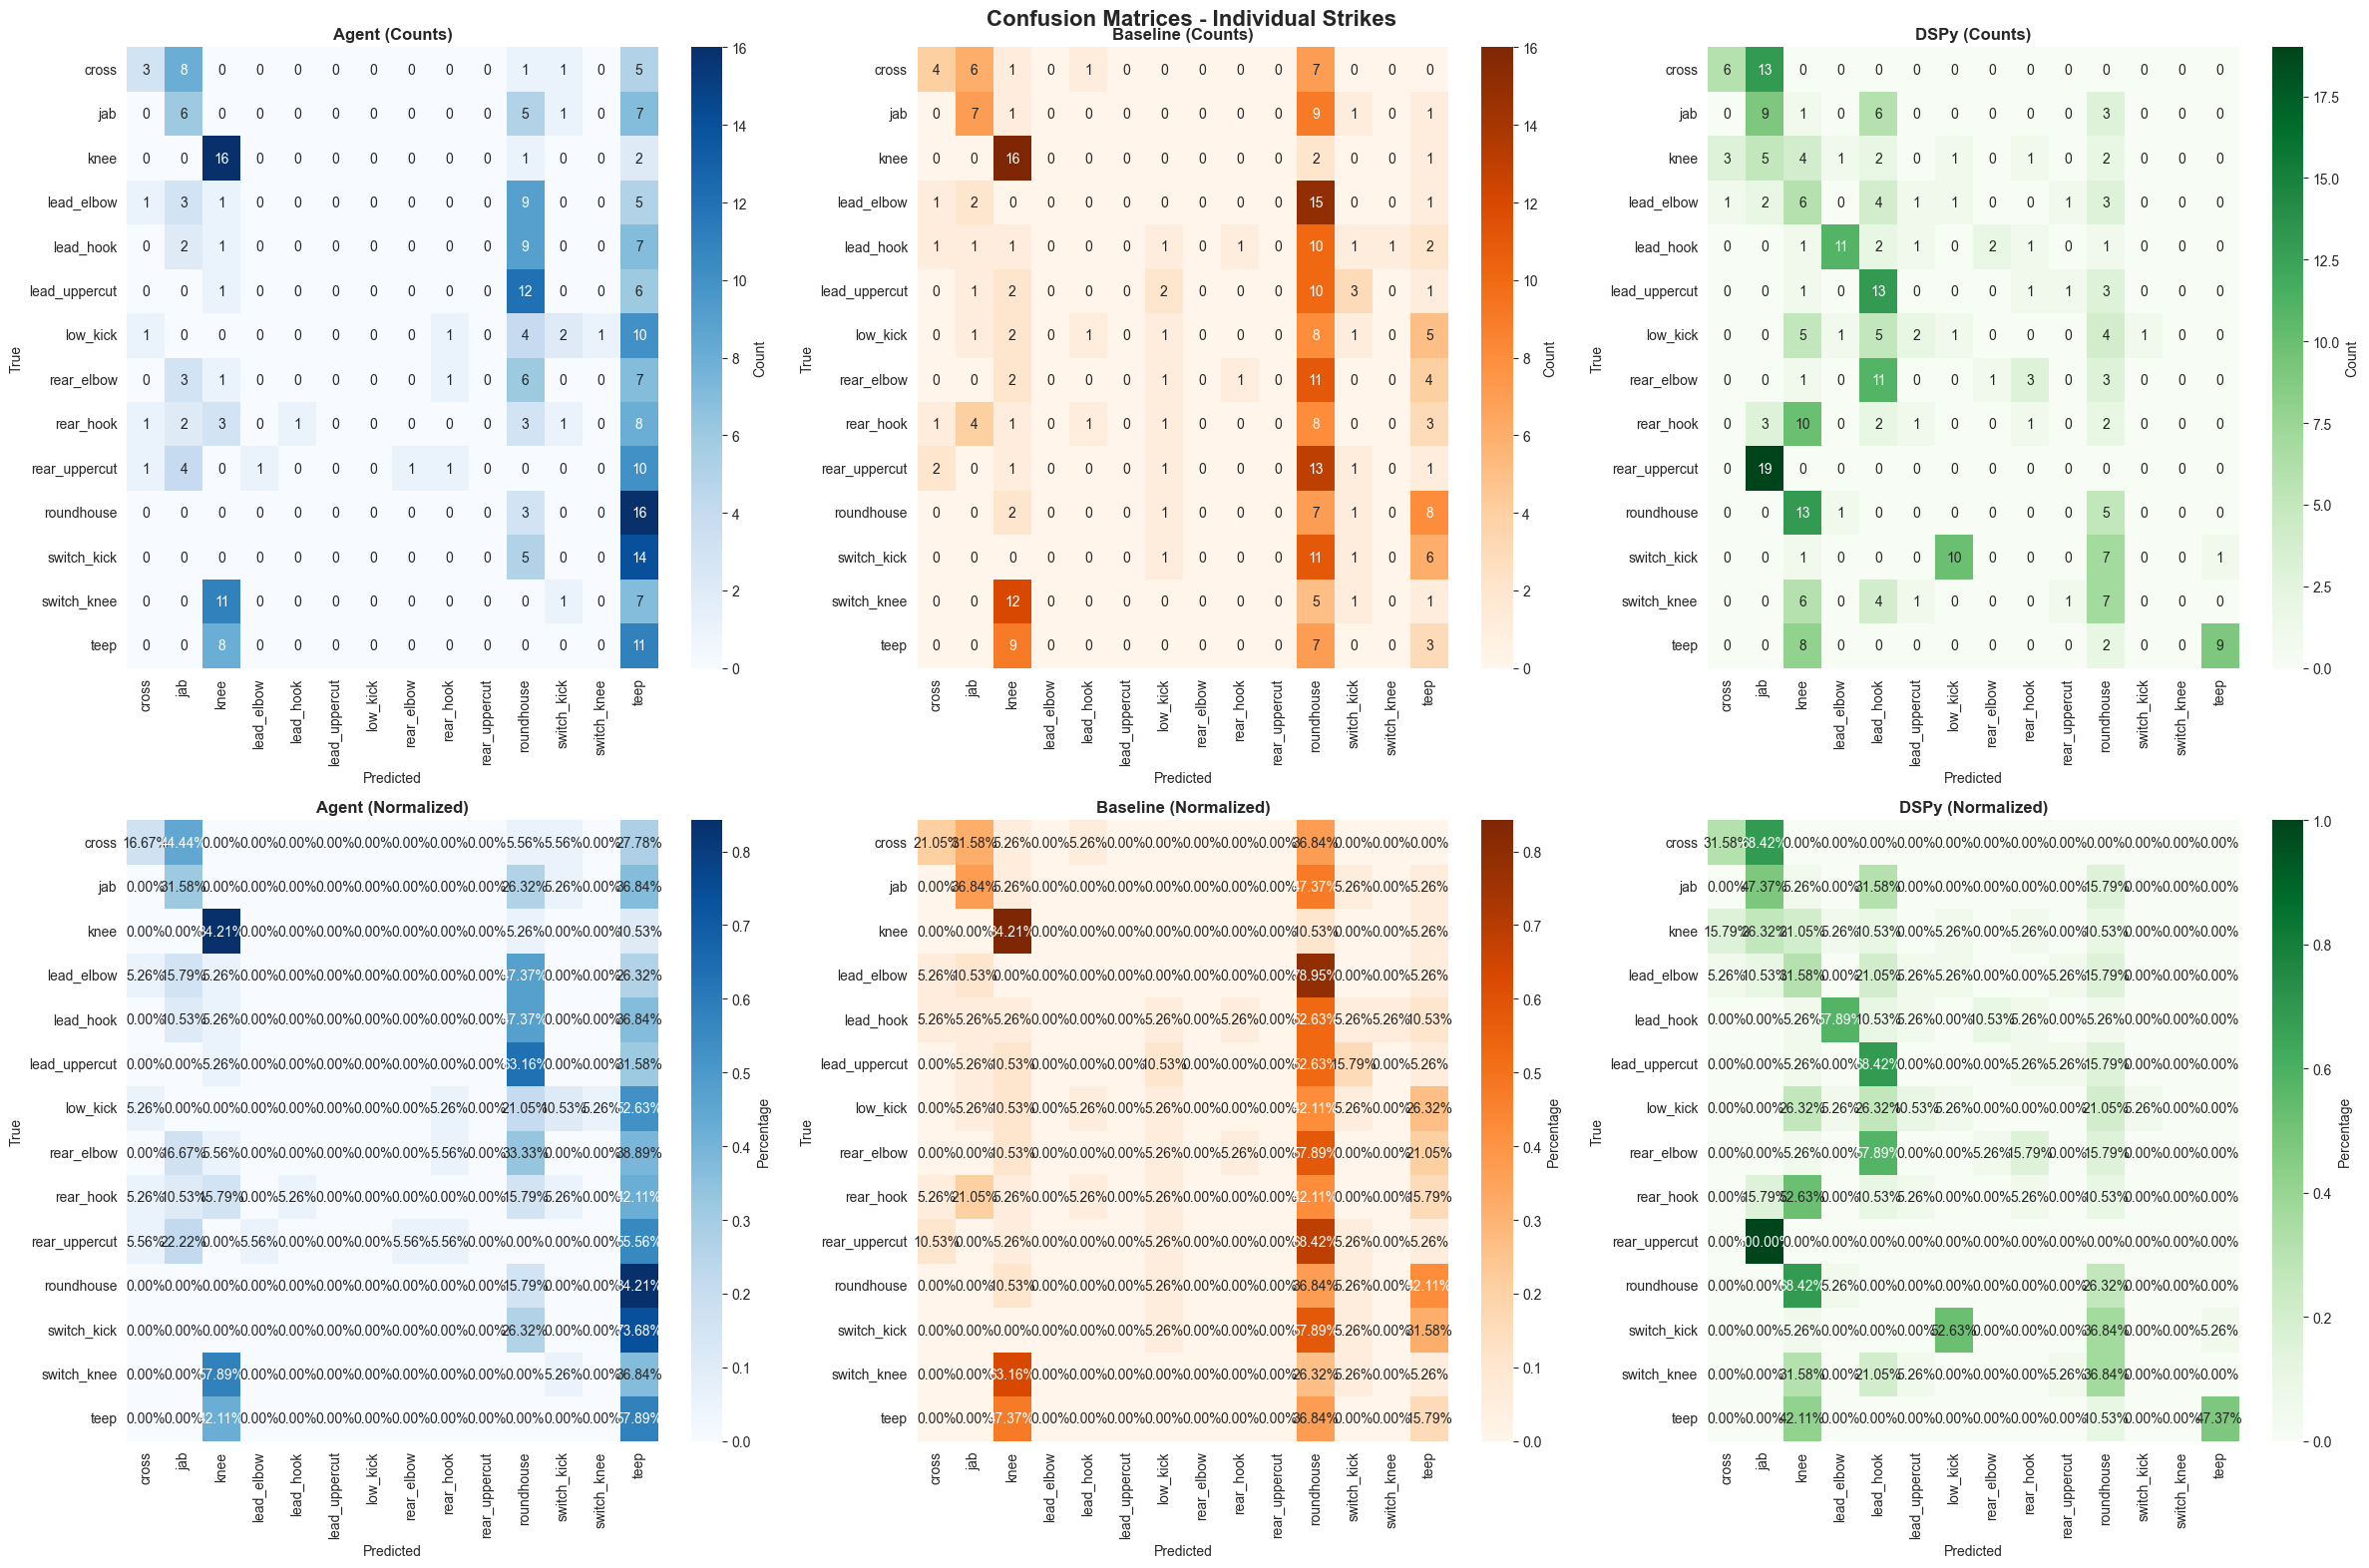

In [86]:
# Filter data for confusion matrices (remove invalid labels)
y_true_agent_cm, y_pred_agent_cm = filter_for_confusion_matrix(y_true_agent, y_pred_agent, all_labels, verbose=True)
y_true_baseline_cm, y_pred_baseline_cm = filter_for_confusion_matrix(y_true_baseline, y_pred_baseline, all_labels, verbose=True)
y_true_dspy_cm, y_pred_dspy_cm = filter_for_confusion_matrix(y_true_dspy, y_pred_dspy, all_labels, verbose=True)

# Generate confusion matrices
cm_agent = confusion_matrix(y_true_agent_cm, y_pred_agent_cm, labels=all_labels)
cm_baseline = confusion_matrix(y_true_baseline_cm, y_pred_baseline_cm, labels=all_labels)
cm_dspy = confusion_matrix(y_true_dspy_cm, y_pred_dspy_cm, labels=all_labels)

# Normalize confusion matrices
cm_agent_norm = cm_agent.astype('float') / (cm_agent.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_baseline_norm = cm_baseline.astype('float') / (cm_baseline.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_dspy_norm = cm_dspy.astype('float') / (cm_dspy.sum(axis=1)[:, np.newaxis] + 1e-10)

# Create side-by-side confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(24, 16))
fig.suptitle('Confusion Matrices - Individual Strikes', fontsize=16, fontweight='bold')

# Raw counts
sns.heatmap(cm_agent, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Count'})
axes[0, 0].set_title('Agent (Counts)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('True')

sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Oranges', ax=axes[0, 1],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Count'})
axes[0, 1].set_title('Baseline (Counts)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('True')

sns.heatmap(cm_dspy, annot=True, fmt='d', cmap='Greens', ax=axes[0, 2],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Count'})
axes[0, 2].set_title('DSPy (Counts)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Predicted')
axes[0, 2].set_ylabel('True')

# Normalized percentages
sns.heatmap(cm_agent_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1, 0],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Percentage'})
axes[1, 0].set_title('Agent (Normalized)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('True')

sns.heatmap(cm_baseline_norm, annot=True, fmt='.2%', cmap='Oranges', ax=axes[1, 1],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Percentage'})
axes[1, 1].set_title('Baseline (Normalized)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('True')

sns.heatmap(cm_dspy_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1, 2],
            xticklabels=all_labels, yticklabels=all_labels, cbar_kws={'label': 'Percentage'})
axes[1, 2].set_title('DSPy (Normalized)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Predicted')
axes[1, 2].set_ylabel('True')

plt.tight_layout()
plt.show()


### 2.4 Per-Class Accuracy Breakdown


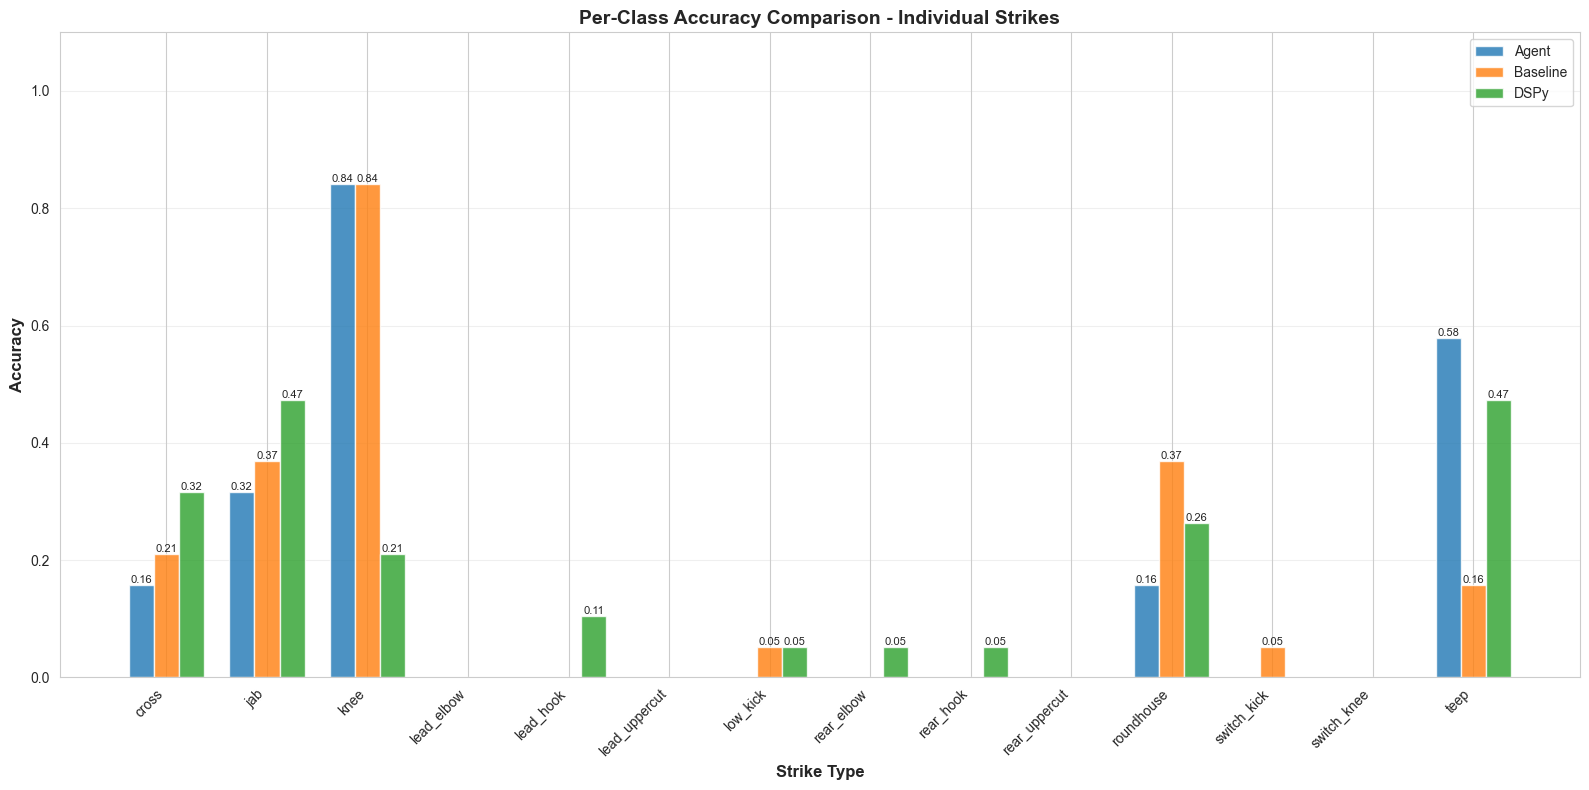


Best performing approach per strike type:
cross               : DSPy       (0.3158)
jab                 : DSPy       (0.4737)
knee                : Agent      (0.8421)
lead_elbow          : Agent      (0.0000)
lead_hook           : DSPy       (0.1053)
lead_uppercut       : Agent      (0.0000)
low_kick            : Baseline   (0.0526)
rear_elbow          : DSPy       (0.0526)
rear_hook           : DSPy       (0.0526)
rear_uppercut       : Agent      (0.0000)
roundhouse          : Baseline   (0.3684)
switch_kick         : Baseline   (0.0526)
switch_knee         : Agent      (0.0000)
teep                : Agent      (0.5789)


In [87]:
# Create bar chart comparing accuracy per strike type
accuracy_comparison = pd.DataFrame({
    'Agent': [acc_agent[label] for label in all_labels],
    'Baseline': [acc_baseline[label] for label in all_labels],
    'DSPy': [acc_dspy[label] for label in all_labels]
}, index=all_labels)

fig, ax = plt.subplots(figsize=(16, 8))
x = np.arange(len(all_labels))
width = 0.25

bars1 = ax.bar(x - width, accuracy_comparison['Agent'], width, 
               label='Agent', color=COLORS['Agent'], alpha=0.8)
bars2 = ax.bar(x, accuracy_comparison['Baseline'], width, 
               label='Baseline', color=COLORS['Baseline'], alpha=0.8)
bars3 = ax.bar(x + width, accuracy_comparison['DSPy'], width, 
               label='DSPy', color=COLORS['DSPy'], alpha=0.8)

ax.set_xlabel('Strike Type', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_title('Per-Class Accuracy Comparison - Individual Strikes', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(all_labels, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.01:  # Only label if significant
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

# Highlight best performing approach per class
print("\nBest performing approach per strike type:")
print("=" * 60)
for label in all_labels:
    best_acc = max(acc_agent[label], acc_baseline[label], acc_dspy[label])
    if acc_agent[label] == best_acc:
        best = 'Agent'
    elif acc_baseline[label] == best_acc:
        best = 'Baseline'
    else:
        best = 'DSPy'
    print(f"{label:20s}: {best:10s} ({best_acc:.4f})")


## Section 3: Single Combo Metrics


In [88]:
# Extract data for single combos
def extract_combo_data(results):
    """Extract true and predicted strikes from combo results."""
    y_true = []
    y_pred = []
    levenshtein_sims = []
    for r in results['results']:
        true_strikes = r.get('true_strikes', [])
        pred_strikes = r.get('predicted_strikes', [])
        
        # Flatten for confusion matrix
        y_true.extend(true_strikes)
        y_pred.extend(pred_strikes)
        
        # Calculate Levenshtein similarity per combo
        sim = calculate_levenshtein_similarity(true_strikes, pred_strikes)
        levenshtein_sims.append(sim)
    
    return y_true, y_pred, levenshtein_sims

y_true_combo_agent, y_pred_combo_agent, lev_agent = extract_combo_data(combo_agent)
y_true_combo_baseline, y_pred_combo_baseline, lev_baseline = extract_combo_data(combo_baseline)
y_true_combo_dspy, y_pred_combo_dspy, lev_dspy = extract_combo_data(combo_dspy)

# Get all unique labels for combos
all_combo_labels = sorted(set(y_true_combo_agent + y_true_combo_baseline + y_true_combo_dspy + 
                              y_pred_combo_agent + y_pred_combo_baseline + y_pred_combo_dspy))

print(f"Total unique strike types in combos: {len(all_combo_labels)}")
print(f"Average Levenshtein similarity - Agent: {np.mean(lev_agent):.4f}")
print(f"Average Levenshtein similarity - Baseline: {np.mean(lev_baseline):.4f}")
print(f"Average Levenshtein similarity - DSPy: {np.mean(lev_dspy):.4f}")


Total unique strike types in combos: 16
Average Levenshtein similarity - Agent: 0.4258
Average Levenshtein similarity - Baseline: 0.4372
Average Levenshtein similarity - DSPy: 0.5148


### 3.1 Overall Metrics Table (Side-by-Side)


In [89]:
# Calculate overall metrics for combos
metrics_combo_agent, per_class_combo_agent, _ = calculate_classification_metrics(
    y_true_combo_agent, y_pred_combo_agent, all_combo_labels
)
metrics_combo_baseline, per_class_combo_baseline, _ = calculate_classification_metrics(
    y_true_combo_baseline, y_pred_combo_baseline, all_combo_labels
)
metrics_combo_dspy, per_class_combo_dspy, _ = calculate_classification_metrics(
    y_true_combo_dspy, y_pred_combo_dspy, all_combo_labels
)

# Get exact match and sequence accuracy from results
combo_comparison_df = pd.DataFrame({
    'Agent': [
        combo_agent['metrics']['exact_match_accuracy'],
        combo_agent['metrics']['average_sequence_accuracy'],
        np.mean(lev_agent),
        metrics_combo_agent['macro_f1'],
        metrics_combo_agent['micro_f1']
    ],
    'Baseline': [
        combo_baseline['metrics']['exact_match_accuracy'],
        combo_baseline['metrics']['average_sequence_accuracy'],
        np.mean(lev_baseline),
        metrics_combo_baseline['macro_f1'],
        metrics_combo_baseline['micro_f1']
    ],
    'DSPy': [
        combo_dspy['metrics']['exact_match_accuracy'],
        combo_dspy['metrics']['average_sequence_accuracy'],
        np.mean(lev_dspy),
        metrics_combo_dspy['macro_f1'],
        metrics_combo_dspy['micro_f1']
    ]
}, index=['Exact Match Accuracy', 'Average Sequence Accuracy', 
          'Average Levenshtein Similarity', 'Macro F1', 'Micro F1'])

print("Overall Metrics Comparison (Single Combos)")
print("=" * 60)
print(combo_comparison_df.round(4))
print("\nBest performing approach per metric:")
for metric in combo_comparison_df.index:
    best = combo_comparison_df.loc[metric].idxmax()
    print(f"  {metric}: {best} ({combo_comparison_df.loc[metric, best]:.4f})")



FILTERING REPORT for calculate_classification_metrics
Total pairs: 90
Valid pairs (kept): 50
Filtered pairs (removed): 40 (44.44%)


FILTERING REPORT for calculate_classification_metrics
Total pairs: 90
Valid pairs (kept): 62
Filtered pairs (removed): 28 (31.11%)


FILTERING REPORT for calculate_classification_metrics
Total pairs: 90
Valid pairs (kept): 87
Filtered pairs (removed): 3 (3.33%)

Overall Metrics Comparison (Single Combos)
                       Agent  Baseline    DSPy
Exact Match Accuracy  0.0400    0.0000  0.1200
Average Sequence ...  0.3000    0.3200  0.3993
Average Levenshte...  0.4258    0.4372  0.5148
Macro F1              0.0541    0.0544  0.0770
Micro F1              0.2200    0.1935  0.2644

Best performing approach per metric:
  Exact Match Accuracy: DSPy (0.1200)
  Average Sequence Accuracy: DSPy (0.3993)
  Average Levenshtein Similarity: DSPy (0.5148)
  Macro F1: DSPy (0.0770)
  Micro F1: DSPy (0.2644)


### 3.2 F1-Scores


Per-Strike-Type F1 Scores (Single Combos)
      Strike Type  Agent F1  Baseline F1  DSPy F1  Support
0           cross    0.2609       0.3571   0.3478     11.0
1             jab    0.4516       0.2778   0.3500     14.0
2            knee    0.0000       0.0000   0.0000      3.0
3      lead_elbow    0.0000       0.0000   0.0000      0.0
4       lead_hook    0.0000       0.2353   0.3571      8.0
5       lead_knee    0.0000       0.0000   0.0000      0.0
6   lead_uppercut    0.0000       0.0000   0.0000      3.0
7         lowkick    0.0000       0.0000   0.0000      1.0
8      rear_elbow    0.0000       0.0000   0.0000      2.0
9       rear_hook    0.0000       0.0000   0.0000      1.0
10      rear_knee    0.0000       0.0000   0.0000      0.0
11  rear_uppercut    0.0000       0.0000   0.0000      0.0
12     roundhouse    0.1538       0.0000   0.1765      5.0
13    switch_kick    0.0000       0.0000   0.0000      0.0
14    switch_knee    0.0000       0.0000   0.0000      0.0
15           t

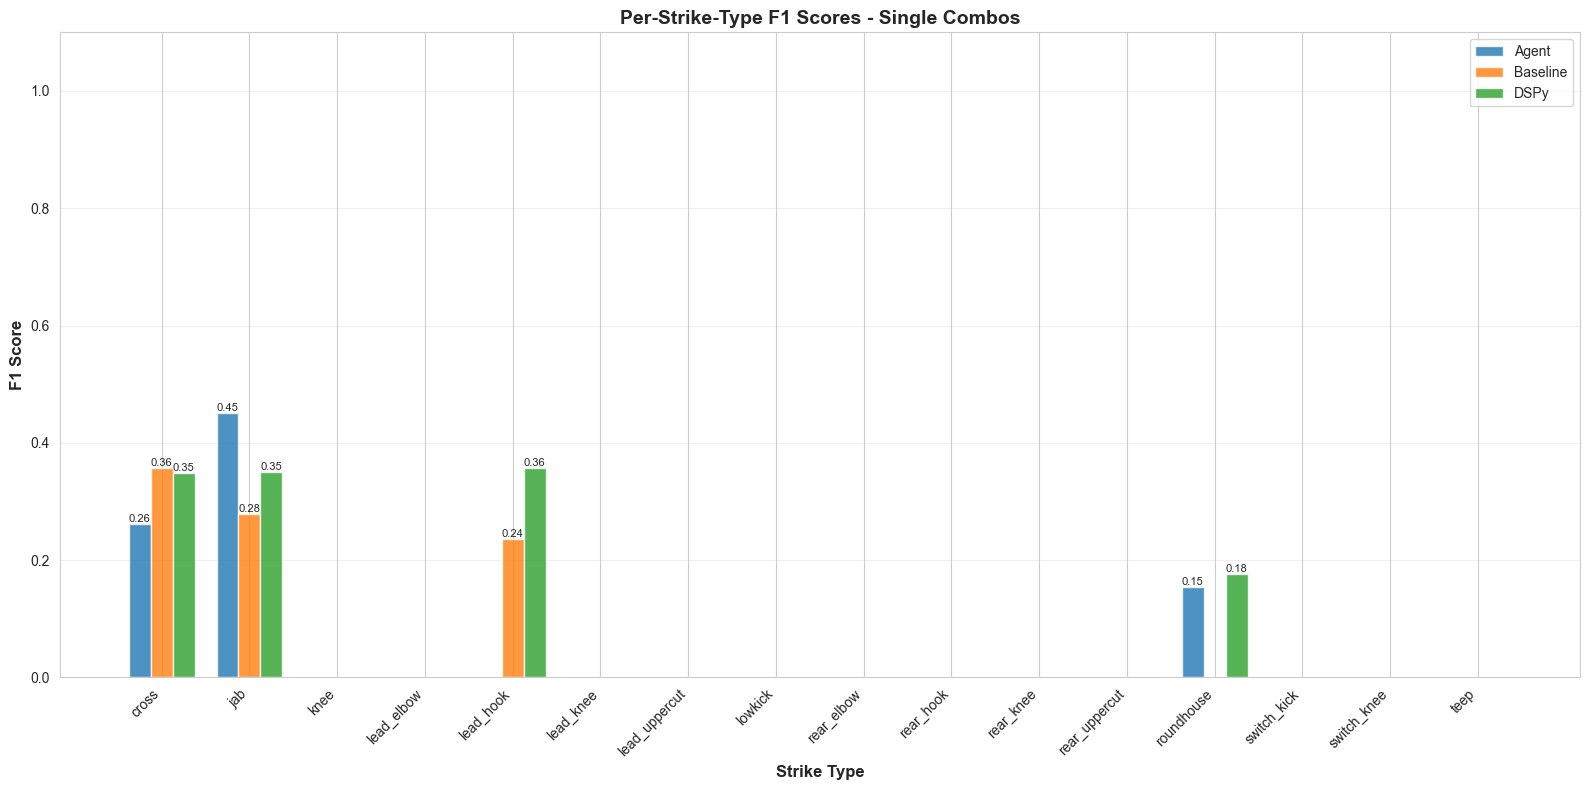

In [90]:
# Extract per-class F1 scores
per_class_combo_agent_dict = extract_per_class_metrics(per_class_combo_agent, all_combo_labels)
per_class_combo_baseline_dict = extract_per_class_metrics(per_class_combo_baseline, all_combo_labels)
per_class_combo_dspy_dict = extract_per_class_metrics(per_class_combo_dspy, all_combo_labels)

# Create F1 comparison table
f1_combo_data = []
for label in all_combo_labels:
    f1_combo_data.append({
        'Strike Type': label,
        'Agent F1': per_class_combo_agent_dict[label]['f1'],
        'Baseline F1': per_class_combo_baseline_dict[label]['f1'],
        'DSPy F1': per_class_combo_dspy_dict[label]['f1'],
        'Support': per_class_combo_agent_dict[label]['support']
    })

f1_combo_df = pd.DataFrame(f1_combo_data)
print("Per-Strike-Type F1 Scores (Single Combos)")
print("=" * 80)
print(f1_combo_df.round(4))

# Visualize F1 scores
f1_comparison_combo = pd.DataFrame({
    'Agent': [per_class_combo_agent_dict[label]['f1'] for label in all_combo_labels],
    'Baseline': [per_class_combo_baseline_dict[label]['f1'] for label in all_combo_labels],
    'DSPy': [per_class_combo_dspy_dict[label]['f1'] for label in all_combo_labels]
}, index=all_combo_labels)

fig, ax = plt.subplots(figsize=(16, 8))
x = np.arange(len(all_combo_labels))
width = 0.25

bars1 = ax.bar(x - width, f1_comparison_combo['Agent'], width, 
               label='Agent', color=COLORS['Agent'], alpha=0.8)
bars2 = ax.bar(x, f1_comparison_combo['Baseline'], width, 
               label='Baseline', color=COLORS['Baseline'], alpha=0.8)
bars3 = ax.bar(x + width, f1_comparison_combo['DSPy'], width, 
               label='DSPy', color=COLORS['DSPy'], alpha=0.8)

ax.set_xlabel('Strike Type', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax.set_title('Per-Strike-Type F1 Scores - Single Combos', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(all_combo_labels, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.01:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


### 3.3 Confusion Matrices



FILTERING REPORT for confusion_matrix
Total pairs: 90
Valid pairs (kept): 50
Filtered pairs (removed): 40 (44.44%)


FILTERING REPORT for confusion_matrix
Total pairs: 90
Valid pairs (kept): 62
Filtered pairs (removed): 28 (31.11%)


FILTERING REPORT for confusion_matrix
Total pairs: 90
Valid pairs (kept): 87
Filtered pairs (removed): 3 (3.33%)



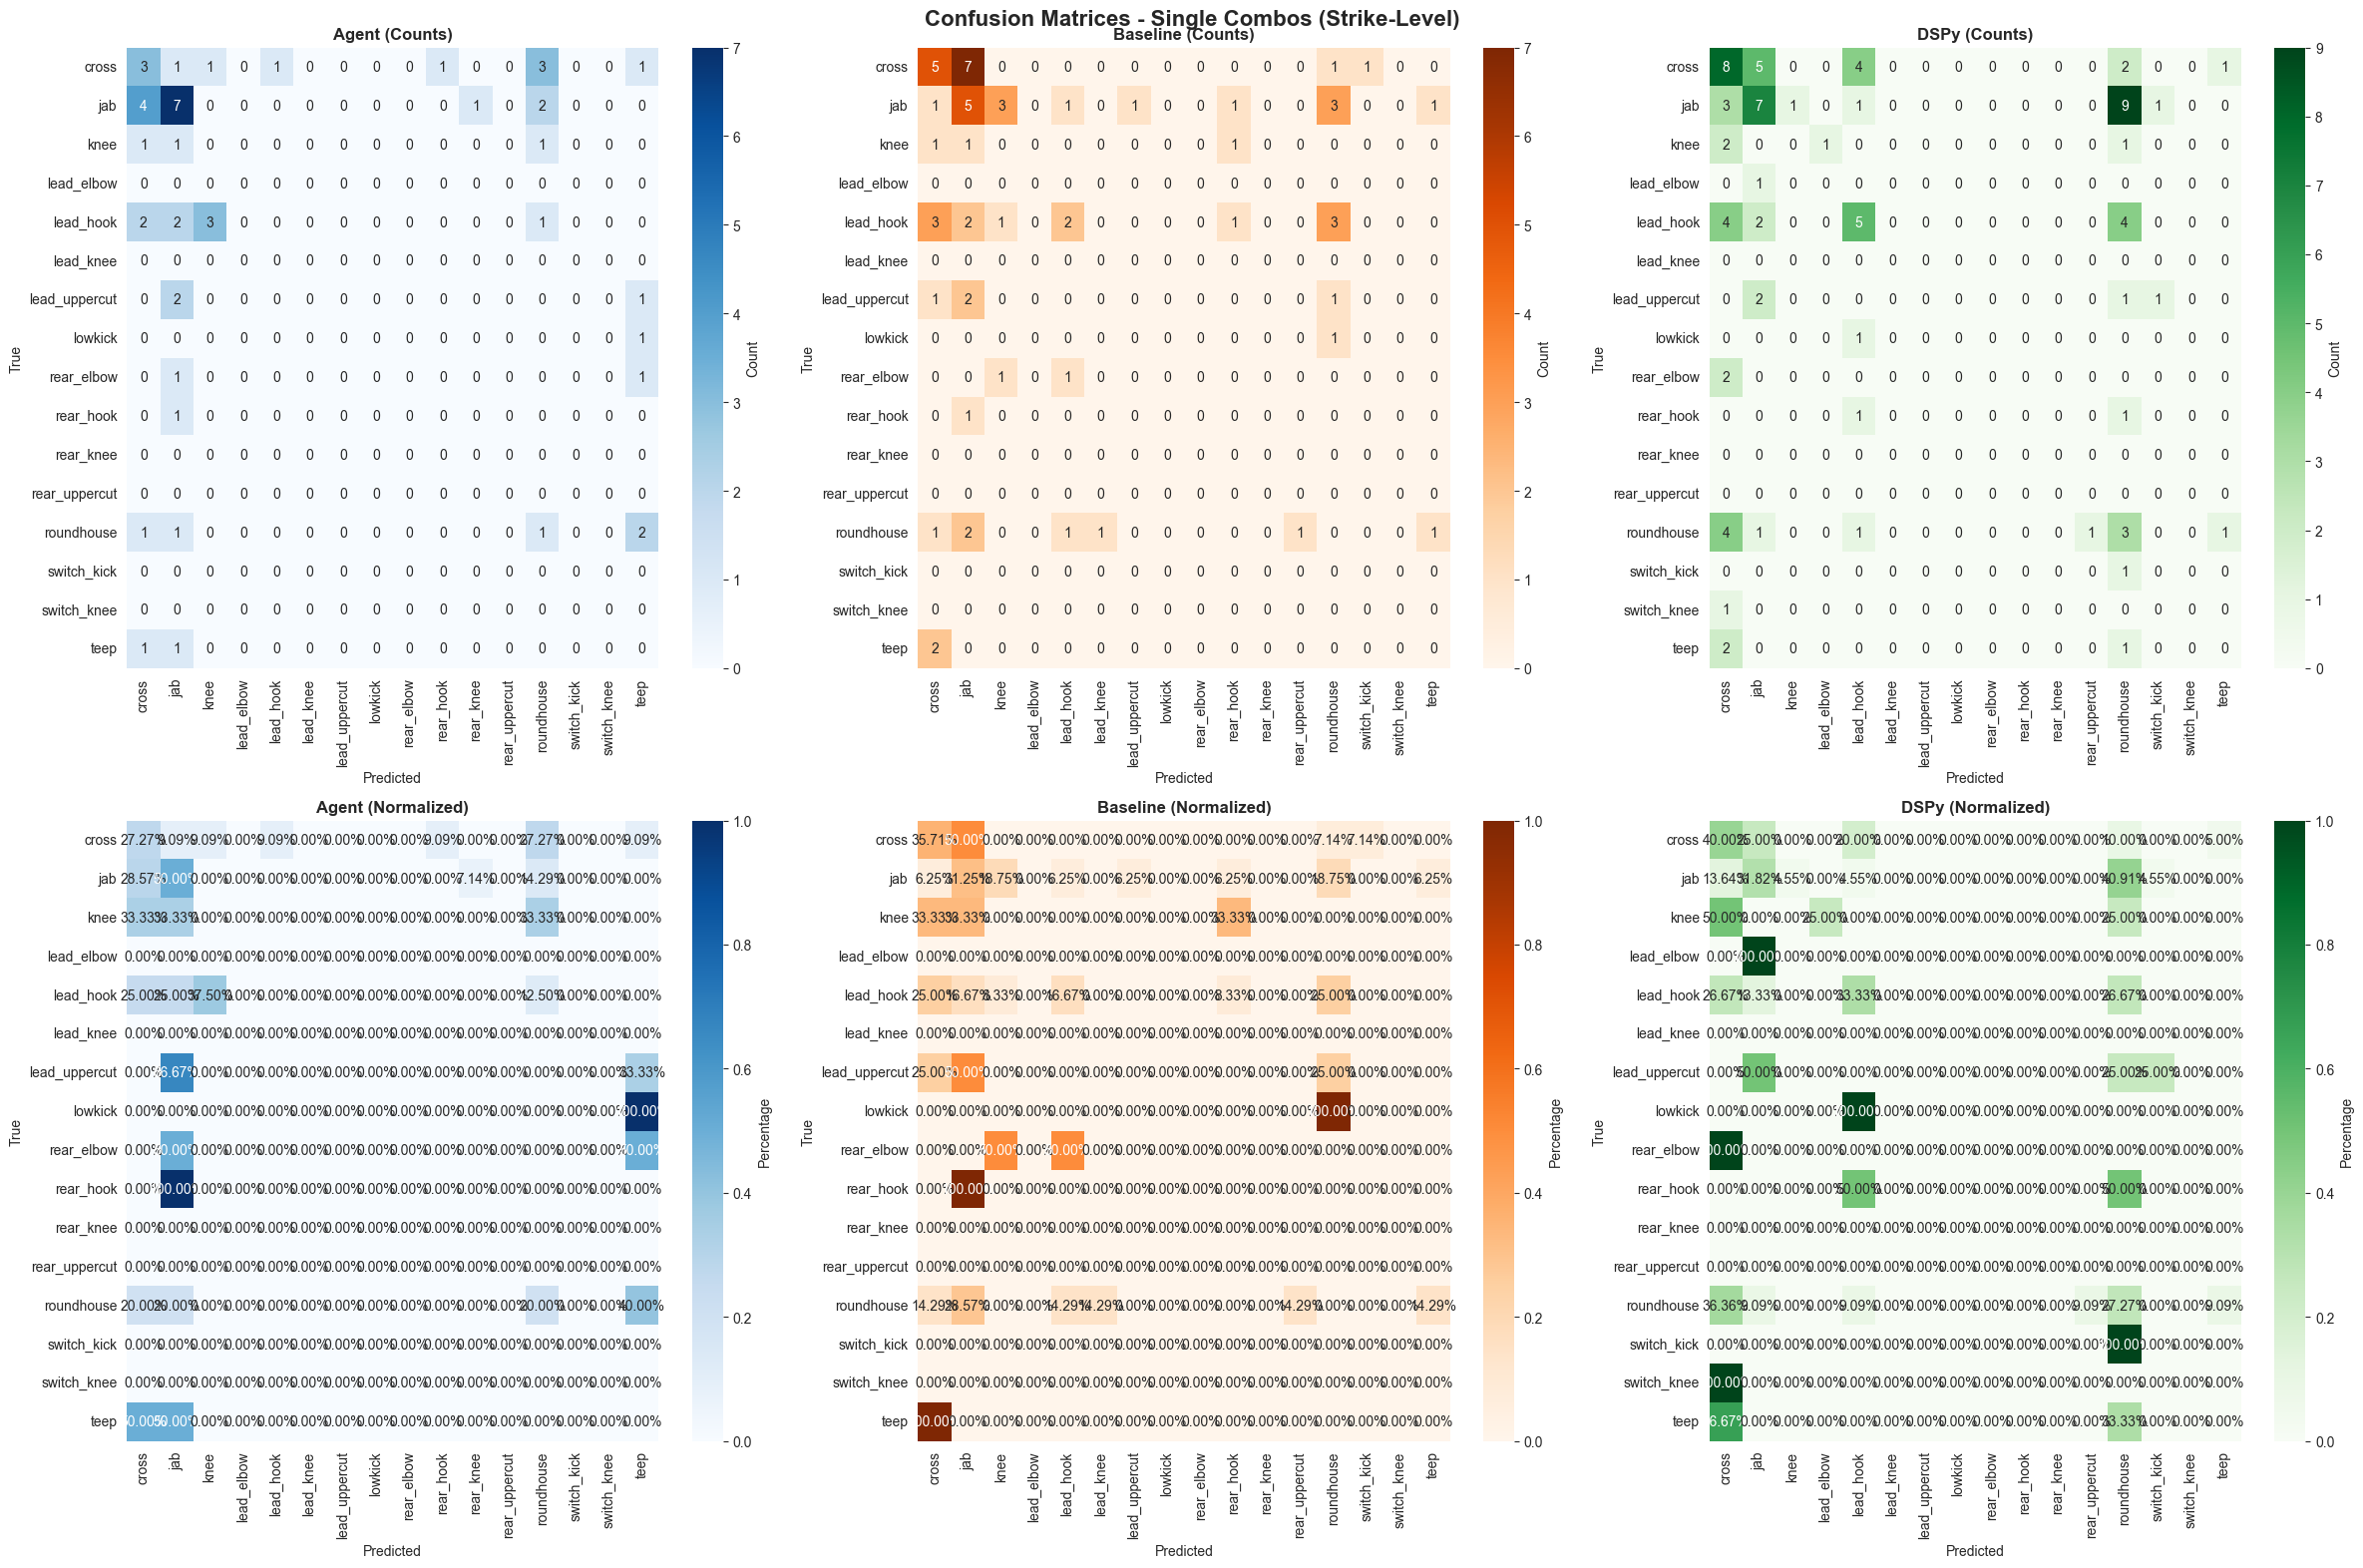

In [91]:
# Filter data for confusion matrices (remove invalid labels)
y_true_combo_agent_cm, y_pred_combo_agent_cm = filter_for_confusion_matrix(y_true_combo_agent, y_pred_combo_agent, all_combo_labels, verbose=True)
y_true_combo_baseline_cm, y_pred_combo_baseline_cm = filter_for_confusion_matrix(y_true_combo_baseline, y_pred_combo_baseline, all_combo_labels, verbose=True)
y_true_combo_dspy_cm, y_pred_combo_dspy_cm = filter_for_confusion_matrix(y_true_combo_dspy, y_pred_combo_dspy, all_combo_labels, verbose=True)

# Generate confusion matrices for combos
cm_combo_agent = confusion_matrix(y_true_combo_agent_cm, y_pred_combo_agent_cm, labels=all_combo_labels)
cm_combo_baseline = confusion_matrix(y_true_combo_baseline_cm, y_pred_combo_baseline_cm, labels=all_combo_labels)
cm_combo_dspy = confusion_matrix(y_true_combo_dspy_cm, y_pred_combo_dspy_cm, labels=all_combo_labels)

# Normalize
cm_combo_agent_norm = cm_combo_agent.astype('float') / (cm_combo_agent.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_combo_baseline_norm = cm_combo_baseline.astype('float') / (cm_combo_baseline.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_combo_dspy_norm = cm_combo_dspy.astype('float') / (cm_combo_dspy.sum(axis=1)[:, np.newaxis] + 1e-10)

# Create side-by-side confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(24, 16))
fig.suptitle('Confusion Matrices - Single Combos (Strike-Level)', fontsize=16, fontweight='bold')

# Raw counts
sns.heatmap(cm_combo_agent, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Count'})
axes[0, 0].set_title('Agent (Counts)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('True')

sns.heatmap(cm_combo_baseline, annot=True, fmt='d', cmap='Oranges', ax=axes[0, 1],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Count'})
axes[0, 1].set_title('Baseline (Counts)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('True')

sns.heatmap(cm_combo_dspy, annot=True, fmt='d', cmap='Greens', ax=axes[0, 2],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Count'})
axes[0, 2].set_title('DSPy (Counts)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Predicted')
axes[0, 2].set_ylabel('True')

# Normalized
sns.heatmap(cm_combo_agent_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1, 0],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Percentage'})
axes[1, 0].set_title('Agent (Normalized)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('True')

sns.heatmap(cm_combo_baseline_norm, annot=True, fmt='.2%', cmap='Oranges', ax=axes[1, 1],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Percentage'})
axes[1, 1].set_title('Baseline (Normalized)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('True')

sns.heatmap(cm_combo_dspy_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1, 2],
            xticklabels=all_combo_labels, yticklabels=all_combo_labels, cbar_kws={'label': 'Percentage'})
axes[1, 2].set_title('DSPy (Normalized)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Predicted')
axes[1, 2].set_ylabel('True')

plt.tight_layout()
plt.show()


### 3.4 Levenshtein Similarity Analysis


Levenshtein Similarity Statistics (Single Combos)
         Agent  Baseline     DSPy
count  25.0000   25.0000  25.0000
mean    0.4258    0.4372   0.5148
std     0.2898    0.2390   0.2724
min     0.0000    0.0000   0.0000
25%     0.2500    0.2500   0.3125
50%     0.5000    0.4167   0.5000
75%     0.6667    0.6667   0.6667
max     1.0000    0.7500   1.0000


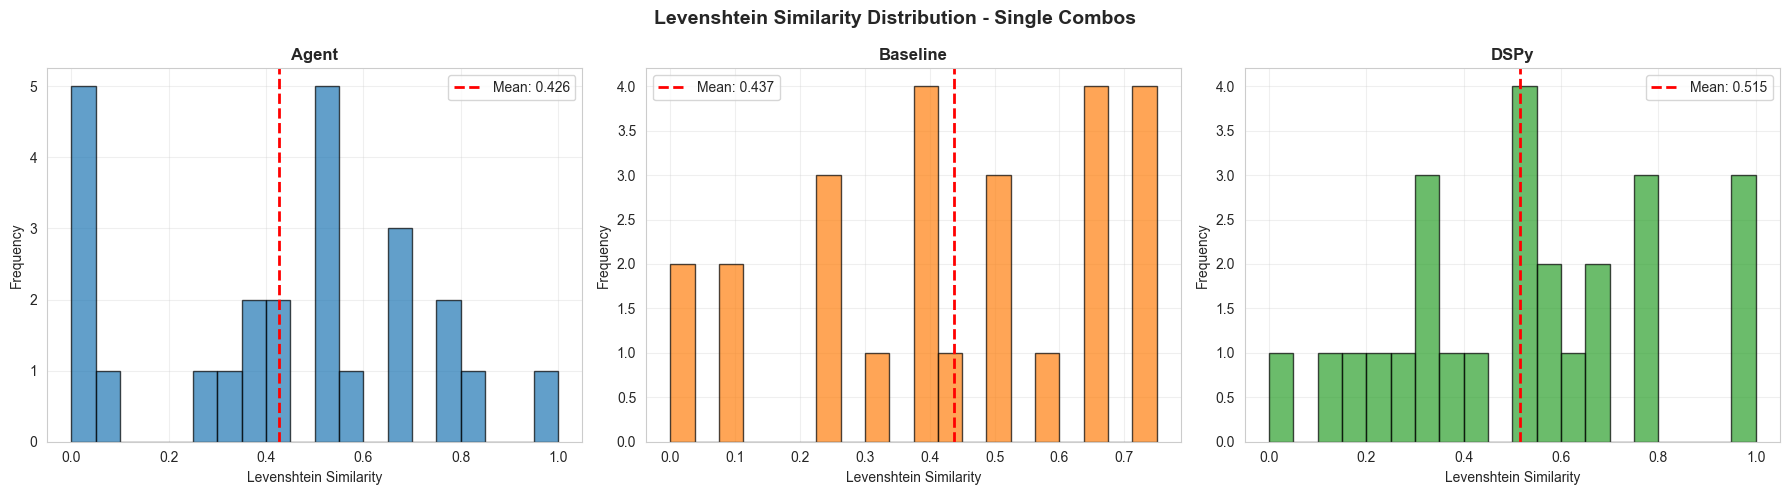

C:\Users\bpohl\AppData\Local\Temp\ipykernel_28748\9171707.py:46: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)


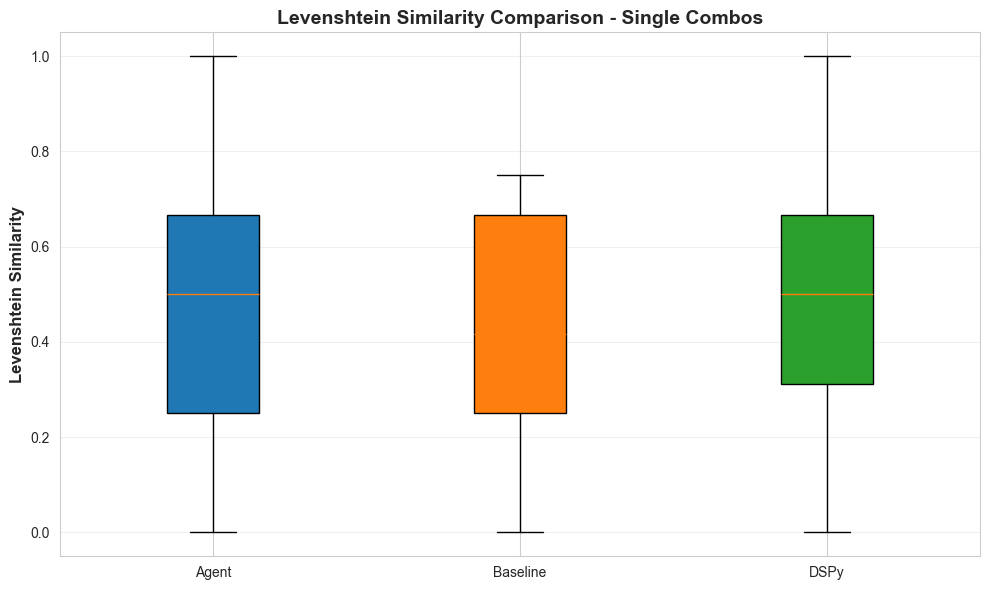

In [92]:
# Create comparison of Levenshtein similarities
lev_comparison_df = pd.DataFrame({
    'Agent': lev_agent,
    'Baseline': lev_baseline,
    'DSPy': lev_dspy
})

print("Levenshtein Similarity Statistics (Single Combos)")
print("=" * 60)
print(lev_comparison_df.describe().round(4))

# Visualize distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Levenshtein Similarity Distribution - Single Combos', fontsize=14, fontweight='bold')

axes[0].hist(lev_agent, bins=20, color=COLORS['Agent'], alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(lev_agent), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(lev_agent):.3f}')
axes[0].set_title('Agent', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Levenshtein Similarity')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(lev_baseline, bins=20, color=COLORS['Baseline'], alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(lev_baseline), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(lev_baseline):.3f}')
axes[1].set_title('Baseline', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Levenshtein Similarity')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].hist(lev_dspy, bins=20, color=COLORS['DSPy'], alpha=0.7, edgecolor='black')
axes[2].axvline(np.mean(lev_dspy), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(lev_dspy):.3f}')
axes[2].set_title('DSPy', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Levenshtein Similarity')
axes[2].set_ylabel('Frequency')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Box plot comparison
fig, ax = plt.subplots(figsize=(10, 6))
box_data = [lev_agent, lev_baseline, lev_dspy]
bp = ax.boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)
bp['boxes'][0].set_facecolor(COLORS['Agent'])
bp['boxes'][1].set_facecolor(COLORS['Baseline'])
bp['boxes'][2].set_facecolor(COLORS['DSPy'])
ax.set_ylabel('Levenshtein Similarity', fontsize=12, fontweight='bold')
ax.set_title('Levenshtein Similarity Comparison - Single Combos', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## Section 4: Multiple Combos Metrics


In [93]:
# Extract data for multiple combos
def extract_multiple_combo_data(results):
    """Extract true and predicted strikes from multiple combo results."""
    y_true = []
    y_pred = []
    levenshtein_sims = []
    combo_boundary_accs = []
    
    for r in results['results']:
        true_combos = r.get('true_combos', [])
        pred_combos = r.get('predicted_combos', [])
        
        # Flatten for confusion matrix
        for combo in true_combos:
            y_true.extend(combo)
        for combo in pred_combos:
            y_pred.extend(combo)
        
        # Calculate Levenshtein similarity per combo (averaged)
        lev_sim = calculate_per_combo_levenshtein(true_combos, pred_combos)
        levenshtein_sims.append(lev_sim)
        
        # Get combo boundary accuracy if available (handle different key names)
        if 'combo_boundary_accuracy' in r:
            combo_boundary_accs.append(r['combo_boundary_accuracy'])
        elif 'boundary_accuracy' in r:
            combo_boundary_accs.append(r['boundary_accuracy'])
    
    return y_true, y_pred, levenshtein_sims, combo_boundary_accs

y_true_mult_agent, y_pred_mult_agent, lev_mult_agent, boundary_agent = extract_multiple_combo_data(multiple_agent)
y_true_mult_baseline, y_pred_mult_baseline, lev_mult_baseline, boundary_baseline = extract_multiple_combo_data(multiple_baseline)
y_true_mult_dspy, y_pred_mult_dspy, lev_mult_dspy, boundary_dspy = extract_multiple_combo_data(multiple_dspy)

# Get all unique labels for multiple combos
all_mult_labels = sorted(set(y_true_mult_agent + y_true_mult_baseline + y_true_mult_dspy + 
                            y_pred_mult_agent + y_pred_mult_baseline + y_pred_mult_dspy))

print(f"Total unique strike types in multiple combos: {len(all_mult_labels)}")
print(f"Average Levenshtein similarity - Agent: {np.mean(lev_mult_agent):.4f}")
print(f"Average Levenshtein similarity - Baseline: {np.mean(lev_mult_baseline):.4f}")
print(f"Average Levenshtein similarity - DSPy: {np.mean(lev_mult_dspy):.4f}")
print(f"Average combo boundary accuracy - Agent: {np.mean(boundary_agent):.4f}")
print(f"Average combo boundary accuracy - Baseline: {np.mean(boundary_baseline):.4f}")
print(f"Average combo boundary accuracy - DSPy: {np.mean(boundary_dspy):.4f}")


Total unique strike types in multiple combos: 17
Average Levenshtein similarity - Agent: 0.2448
Average Levenshtein similarity - Baseline: 0.1770
Average Levenshtein similarity - DSPy: 0.3022
Average combo boundary accuracy - Agent: 0.4817
Average combo boundary accuracy - Baseline: 0.4986
Average combo boundary accuracy - DSPy: 0.4236


### 4.1 Overall Metrics Table (Side-by-Side)


In [94]:
# Calculate overall metrics for multiple combos
metrics_mult_agent, per_class_mult_agent, _ = calculate_classification_metrics(
    y_true_mult_agent, y_pred_mult_agent, all_mult_labels
)
metrics_mult_baseline, per_class_mult_baseline, _ = calculate_classification_metrics(
    y_true_mult_baseline, y_pred_mult_baseline, all_mult_labels
)
metrics_mult_dspy, per_class_mult_dspy, _ = calculate_classification_metrics(
    y_true_mult_dspy, y_pred_mult_dspy, all_mult_labels
)

# Get metrics from results (handle different key names for boundary accuracy)
# Baseline uses 'average_boundary_accuracy', others use 'average_combo_boundary_accuracy'
baseline_boundary_key = 'average_boundary_accuracy' if 'average_boundary_accuracy' in multiple_baseline['metrics'] else 'average_combo_boundary_accuracy'
agent_boundary_key = 'average_combo_boundary_accuracy' if 'average_combo_boundary_accuracy' in multiple_agent['metrics'] else 'average_boundary_accuracy'
dspy_boundary_key = 'average_combo_boundary_accuracy' if 'average_combo_boundary_accuracy' in multiple_dspy['metrics'] else 'average_boundary_accuracy'

mult_comparison_df = pd.DataFrame({
    'Agent': [
        multiple_agent['metrics']['exact_match_accuracy'],
        multiple_agent['metrics']['average_sequence_accuracy'],
        multiple_agent['metrics']['average_combo_count_accuracy'],
        multiple_agent['metrics'].get(agent_boundary_key, 0.0),
        multiple_agent['metrics']['average_combo_wise_accuracy'],
        np.mean(lev_mult_agent),
        metrics_mult_agent['macro_f1'],
        metrics_mult_agent['micro_f1']
    ],
    'Baseline': [
        multiple_baseline['metrics']['exact_match_accuracy'],
        multiple_baseline['metrics']['average_sequence_accuracy'],
        multiple_baseline['metrics']['average_combo_count_accuracy'],
        multiple_baseline['metrics'].get(baseline_boundary_key, 0.0),
        multiple_baseline['metrics']['average_combo_wise_accuracy'],
        np.mean(lev_mult_baseline),
        metrics_mult_baseline['macro_f1'],
        metrics_mult_baseline['micro_f1']
    ],
    'DSPy': [
        multiple_dspy['metrics']['exact_match_accuracy'],
        multiple_dspy['metrics']['average_sequence_accuracy'],
        multiple_dspy['metrics']['average_combo_count_accuracy'],
        multiple_dspy['metrics'].get(dspy_boundary_key, 0.0),
        multiple_dspy['metrics']['average_combo_wise_accuracy'],
        np.mean(lev_mult_dspy),
        metrics_mult_dspy['macro_f1'],
        metrics_mult_dspy['micro_f1']
    ]
}, index=['Exact Match Accuracy', 'Average Sequence Accuracy', 
          'Average Combo Count Accuracy', 'Average Combo Boundary Accuracy (Pause Recognition)',
          'Average Combo-Wise Accuracy', 'Average Levenshtein Similarity',
          'Macro F1', 'Micro F1'])

print("Overall Metrics Comparison (Multiple Combos)")
print("=" * 80)
print(mult_comparison_df.round(4))
print("\nBest performing approach per metric:")
for metric in mult_comparison_df.index:
    best = mult_comparison_df.loc[metric].idxmax()
    print(f"  {metric}: {best} ({mult_comparison_df.loc[metric, best]:.4f})")



FILTERING REPORT for calculate_classification_metrics
Total pairs: 244
Valid pairs (kept): 91
Filtered pairs (removed): 153 (62.70%)


FILTERING REPORT for calculate_classification_metrics
Total pairs: 244
Valid pairs (kept): 52
Filtered pairs (removed): 192 (78.69%)

Overall Metrics Comparison (Multiple Combos)
                       Agent  Baseline    DSPy
Exact Match Accuracy  0.0000    0.0000  0.0000
Average Sequence ...  0.1223    0.1349  0.2016
Average Combo Cou...  0.6692    0.3799  0.7764
Average Combo Bou...  0.4817    0.4986  0.4236
Average Combo-Wis...  0.0326    0.0590  0.0000
Average Levenshte...  0.2448    0.1770  0.3022
Macro F1              0.0482    0.0261  0.0627
Micro F1              0.2088    0.0962  0.1967

Best performing approach per metric:
  Exact Match Accuracy: Agent (0.0000)
  Average Sequence Accuracy: DSPy (0.2016)
  Average Combo Count Accuracy: DSPy (0.7764)
  Average Combo Boundary Accuracy (Pause Recognition): Baseline (0.4986)
  Average Combo-Wise Ac

### 4.2 F1-Scores


Per-Strike-Type F1 Scores (Multiple Combos)
        Strike Type  Agent F1  Baseline F1  DSPy F1  Support
0             cross    0.2667       0.0769   0.2645     18.0
1             elbow    0.0000       0.0000   0.0000      1.0
2               jab    0.4528       0.2000   0.3307     21.0
3              knee    0.0000       0.0000   0.0000      1.0
4        lead_elbow    0.0000       0.0000   0.0000      6.0
5         lead_hook    0.0000       0.0000   0.1515      8.0
6   lead_roundhouse    0.0000       0.0000   0.0000      1.0
7     lead_uppercut    0.0000       0.0000   0.0909     11.0
8          low_kick    0.0000       0.0000   0.0000      0.0
9        rear_elbow    0.0000       0.0000   0.0800     12.0
10        rear_hook    0.0000       0.0000   0.0000      0.0
11    rear_uppercut    0.0000       0.0000   0.0000      1.0
12       roundhouse    0.1000       0.1667   0.1481      7.0
13   spinning_elbow    0.0000       0.0000   0.0000      0.0
14      switch_kick    0.0000       0.000

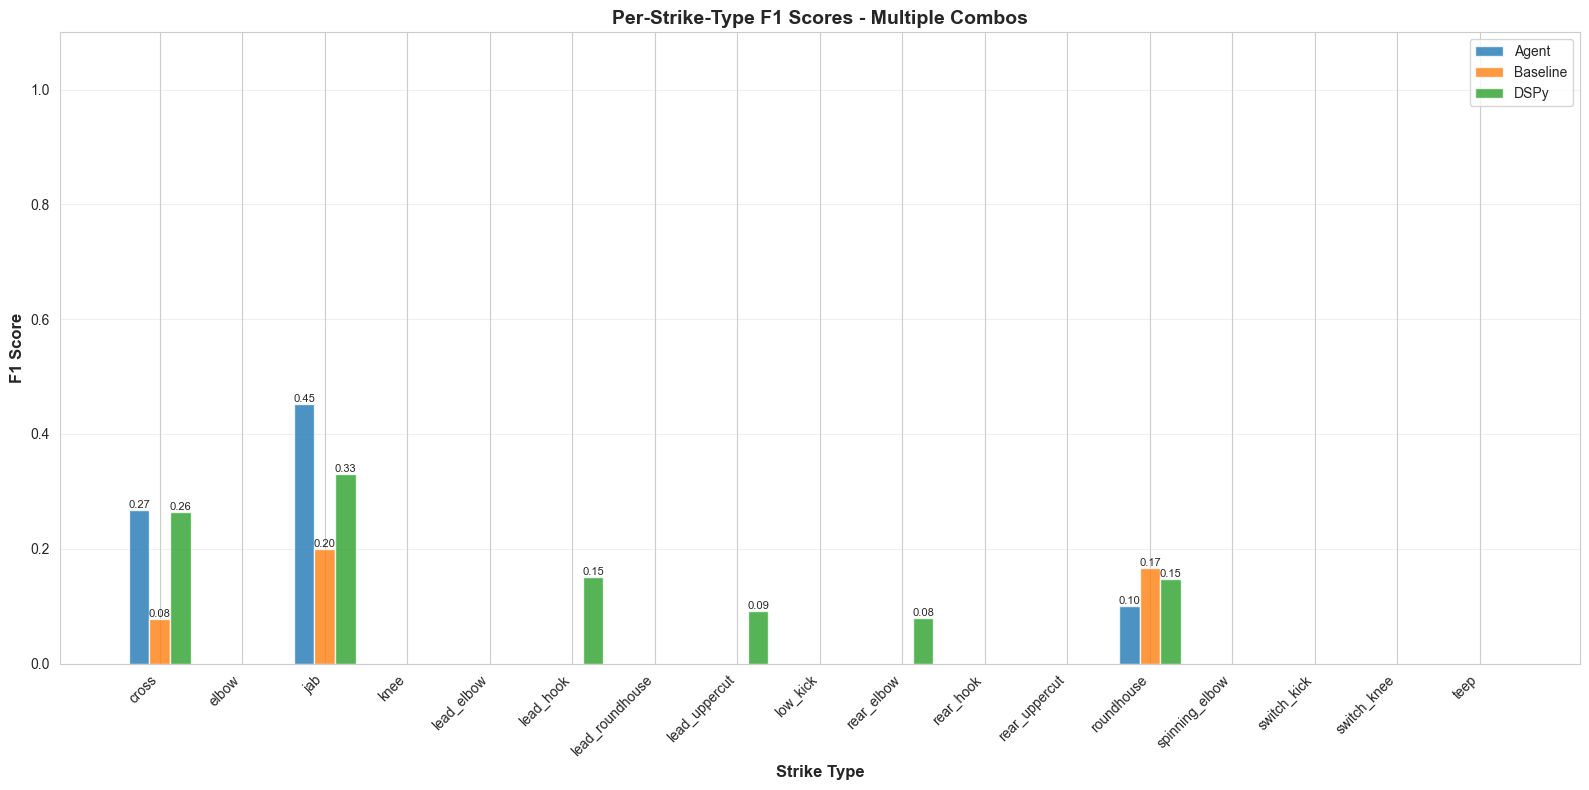

In [95]:
# Extract per-class F1 scores
per_class_mult_agent_dict = extract_per_class_metrics(per_class_mult_agent, all_mult_labels)
per_class_mult_baseline_dict = extract_per_class_metrics(per_class_mult_baseline, all_mult_labels)
per_class_mult_dspy_dict = extract_per_class_metrics(per_class_mult_dspy, all_mult_labels)

# Create F1 comparison table
f1_mult_data = []
for label in all_mult_labels:
    f1_mult_data.append({
        'Strike Type': label,
        'Agent F1': per_class_mult_agent_dict[label]['f1'],
        'Baseline F1': per_class_mult_baseline_dict[label]['f1'],
        'DSPy F1': per_class_mult_dspy_dict[label]['f1'],
        'Support': per_class_mult_agent_dict[label]['support']
    })

f1_mult_df = pd.DataFrame(f1_mult_data)
print("Per-Strike-Type F1 Scores (Multiple Combos)")
print("=" * 80)
print(f1_mult_df.round(4))

# Visualize F1 scores
f1_comparison_mult = pd.DataFrame({
    'Agent': [per_class_mult_agent_dict[label]['f1'] for label in all_mult_labels],
    'Baseline': [per_class_mult_baseline_dict[label]['f1'] for label in all_mult_labels],
    'DSPy': [per_class_mult_dspy_dict[label]['f1'] for label in all_mult_labels]
}, index=all_mult_labels)

fig, ax = plt.subplots(figsize=(16, 8))
x = np.arange(len(all_mult_labels))
width = 0.25

bars1 = ax.bar(x - width, f1_comparison_mult['Agent'], width, 
               label='Agent', color=COLORS['Agent'], alpha=0.8)
bars2 = ax.bar(x, f1_comparison_mult['Baseline'], width, 
               label='Baseline', color=COLORS['Baseline'], alpha=0.8)
bars3 = ax.bar(x + width, f1_comparison_mult['DSPy'], width, 
               label='DSPy', color=COLORS['DSPy'], alpha=0.8)

ax.set_xlabel('Strike Type', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax.set_title('Per-Strike-Type F1 Scores - Multiple Combos', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(all_mult_labels, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        if height > 0.01:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


### 4.3 Confusion Matrices



FILTERING REPORT for confusion_matrix
Total pairs: 244
Valid pairs (kept): 91
Filtered pairs (removed): 153 (62.70%)


FILTERING REPORT for confusion_matrix
Total pairs: 244
Valid pairs (kept): 52
Filtered pairs (removed): 192 (78.69%)



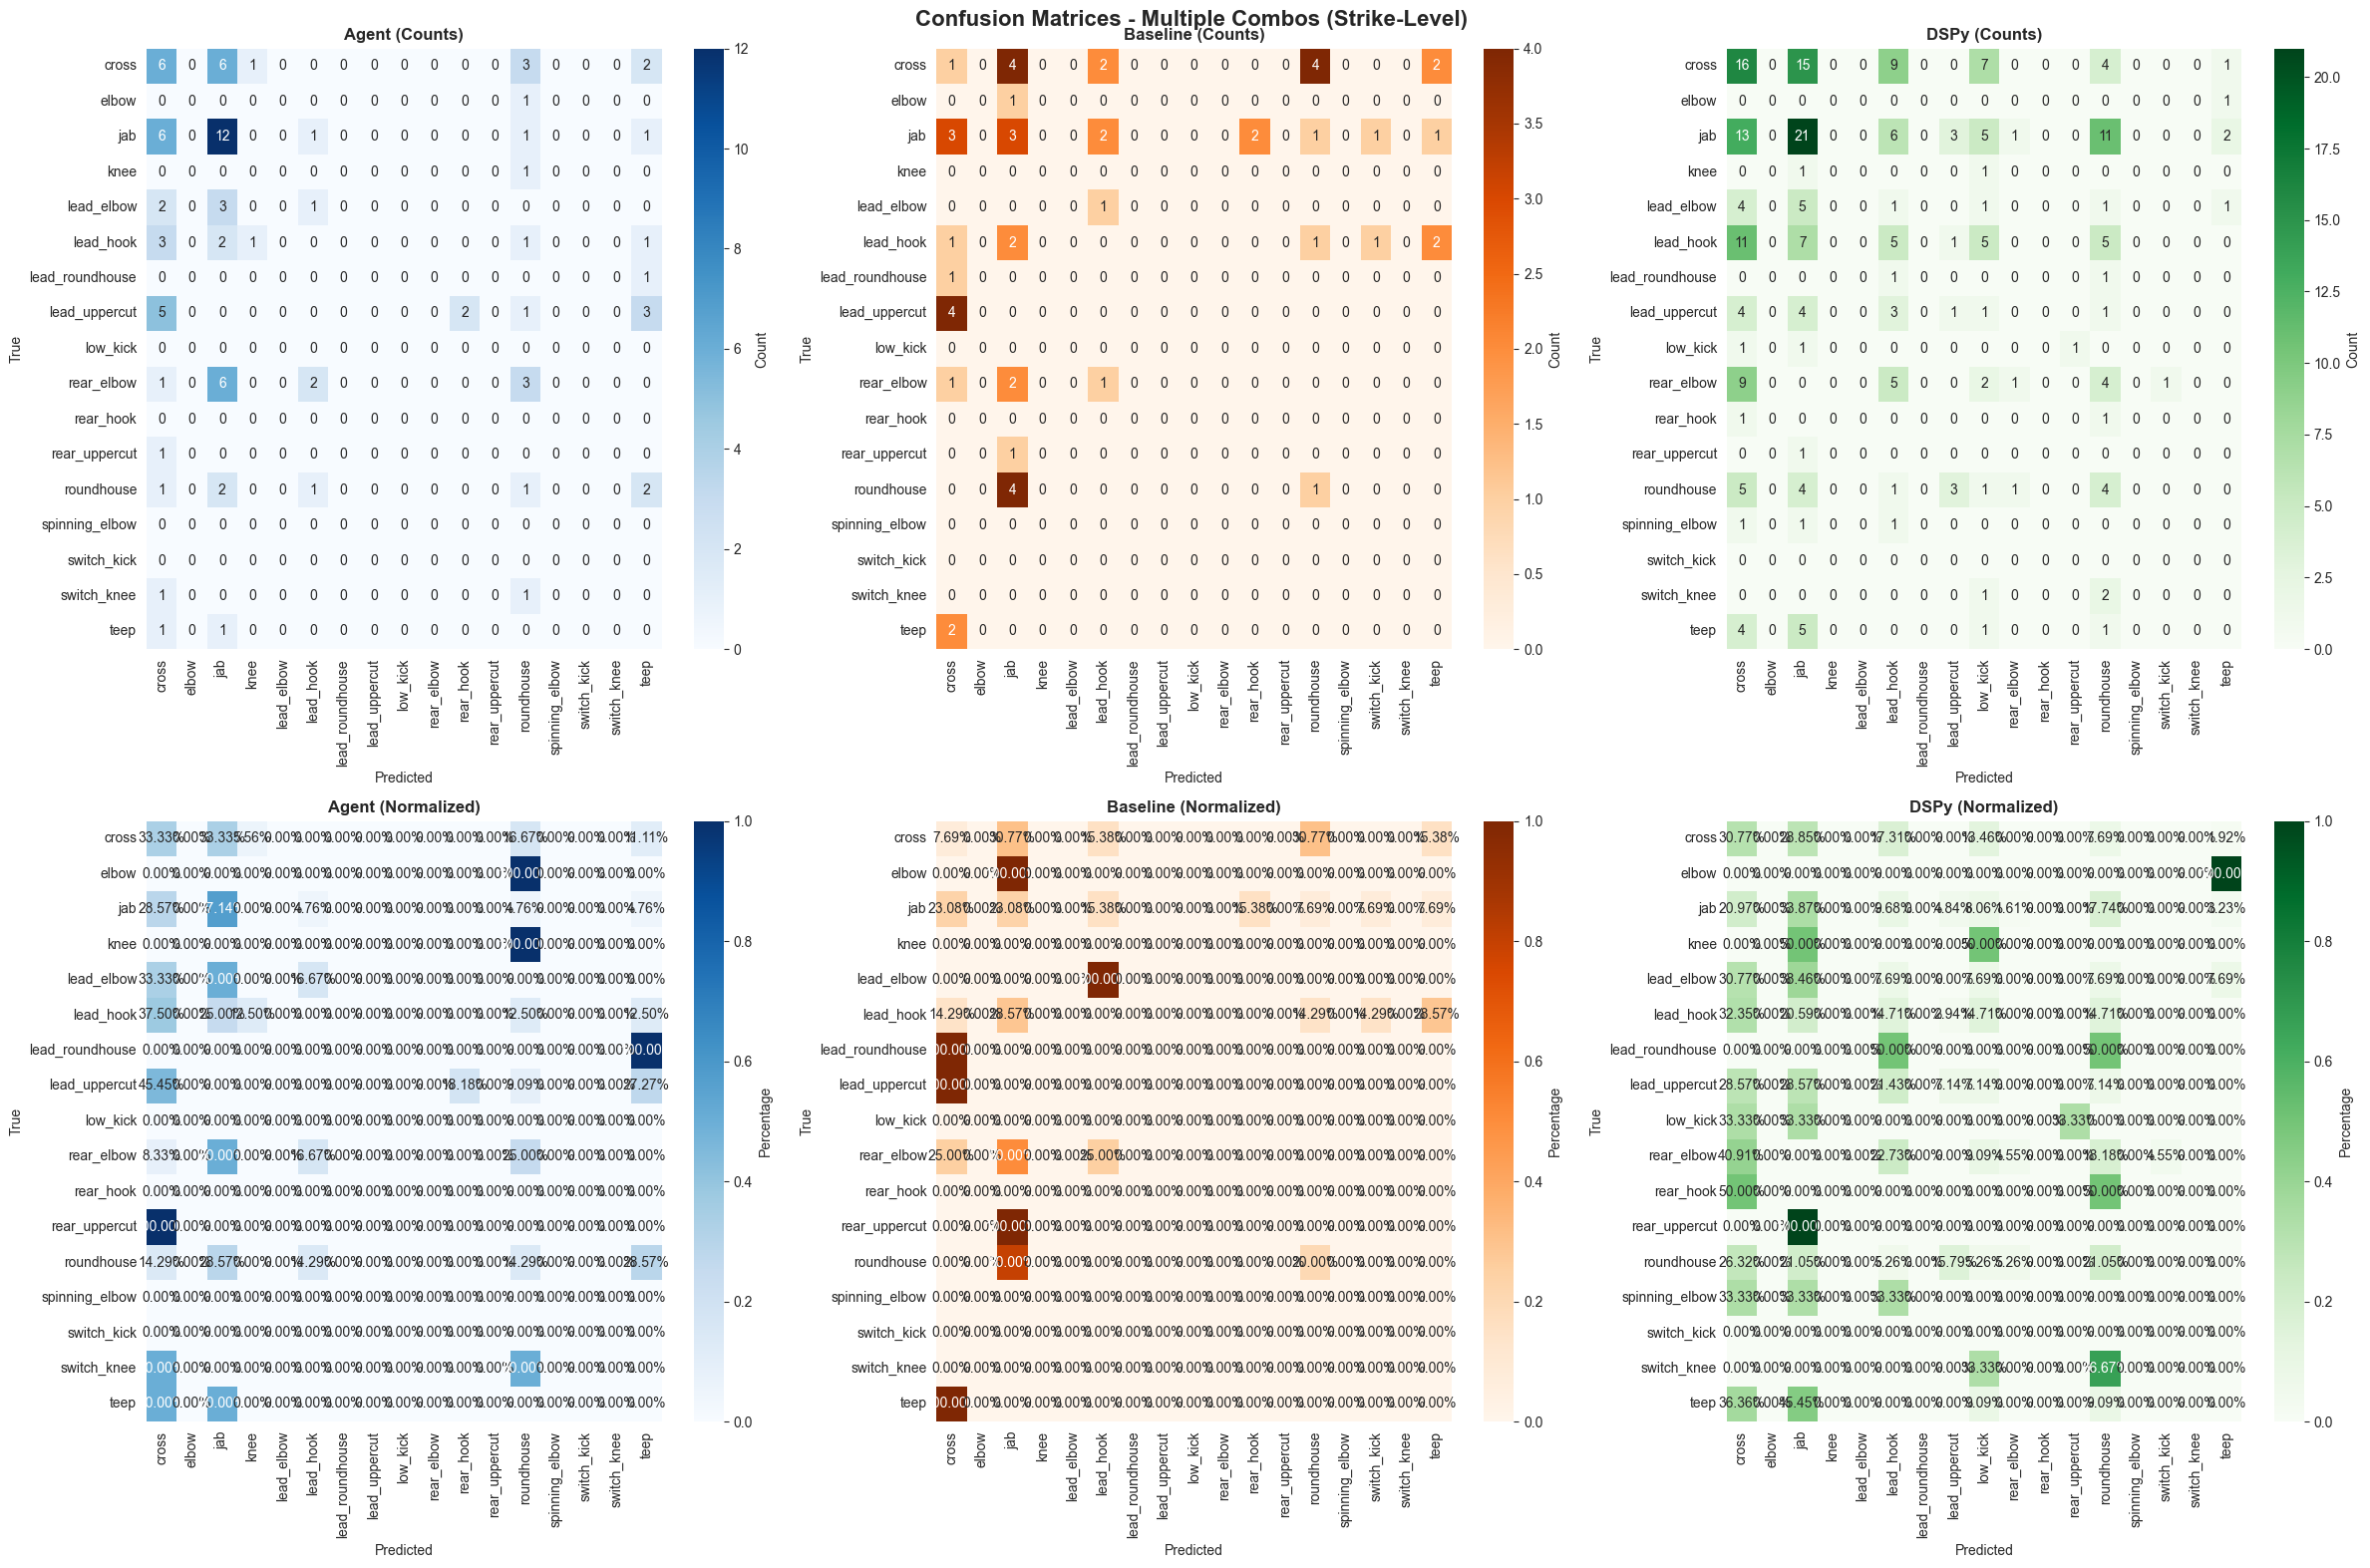

In [96]:
# Filter data for confusion matrices (remove invalid labels)
y_true_mult_agent_cm, y_pred_mult_agent_cm = filter_for_confusion_matrix(y_true_mult_agent, y_pred_mult_agent, all_mult_labels, verbose=True)
y_true_mult_baseline_cm, y_pred_mult_baseline_cm = filter_for_confusion_matrix(y_true_mult_baseline, y_pred_mult_baseline, all_mult_labels, verbose=True)
y_true_mult_dspy_cm, y_pred_mult_dspy_cm = filter_for_confusion_matrix(y_true_mult_dspy, y_pred_mult_dspy, all_mult_labels, verbose=True)

# Generate confusion matrices for multiple combos
cm_mult_agent = confusion_matrix(y_true_mult_agent_cm, y_pred_mult_agent_cm, labels=all_mult_labels)
cm_mult_baseline = confusion_matrix(y_true_mult_baseline_cm, y_pred_mult_baseline_cm, labels=all_mult_labels)
cm_mult_dspy = confusion_matrix(y_true_mult_dspy_cm, y_pred_mult_dspy_cm, labels=all_mult_labels)

# Normalize
cm_mult_agent_norm = cm_mult_agent.astype('float') / (cm_mult_agent.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_mult_baseline_norm = cm_mult_baseline.astype('float') / (cm_mult_baseline.sum(axis=1)[:, np.newaxis] + 1e-10)
cm_mult_dspy_norm = cm_mult_dspy.astype('float') / (cm_mult_dspy.sum(axis=1)[:, np.newaxis] + 1e-10)

# Create side-by-side confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(24, 16))
fig.suptitle('Confusion Matrices - Multiple Combos (Strike-Level)', fontsize=16, fontweight='bold')

# Raw counts
sns.heatmap(cm_mult_agent, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Count'})
axes[0, 0].set_title('Agent (Counts)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('True')

sns.heatmap(cm_mult_baseline, annot=True, fmt='d', cmap='Oranges', ax=axes[0, 1],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Count'})
axes[0, 1].set_title('Baseline (Counts)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('True')

sns.heatmap(cm_mult_dspy, annot=True, fmt='d', cmap='Greens', ax=axes[0, 2],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Count'})
axes[0, 2].set_title('DSPy (Counts)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Predicted')
axes[0, 2].set_ylabel('True')

# Normalized
sns.heatmap(cm_mult_agent_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1, 0],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Percentage'})
axes[1, 0].set_title('Agent (Normalized)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('True')

sns.heatmap(cm_mult_baseline_norm, annot=True, fmt='.2%', cmap='Oranges', ax=axes[1, 1],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Percentage'})
axes[1, 1].set_title('Baseline (Normalized)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('True')

sns.heatmap(cm_mult_dspy_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1, 2],
            xticklabels=all_mult_labels, yticklabels=all_mult_labels, cbar_kws={'label': 'Percentage'})
axes[1, 2].set_title('DSPy (Normalized)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Predicted')
axes[1, 2].set_ylabel('True')

plt.tight_layout()
plt.show()


### 4.4 Levenshtein Similarity Analysis


Levenshtein Similarity Statistics (Multiple Combos)
         Agent  Baseline     DSPy
count  24.0000   24.0000  24.0000
mean    0.2448    0.1770   0.3022
std     0.1520    0.1220   0.0948
min     0.0000    0.0000   0.1250
25%     0.1458    0.1083   0.2396
50%     0.2708    0.1361   0.2917
75%     0.3573    0.2500   0.3542
max     0.5833    0.5000   0.5278


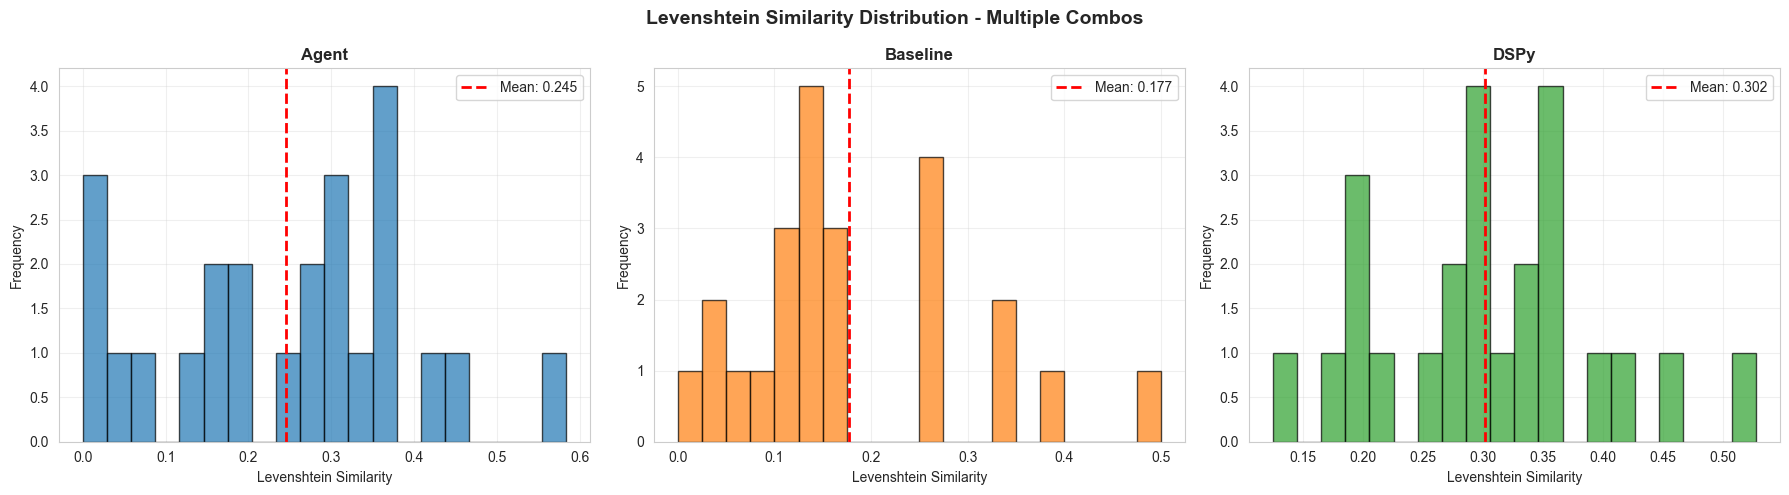

C:\Users\bpohl\AppData\Local\Temp\ipykernel_28748\950957774.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)


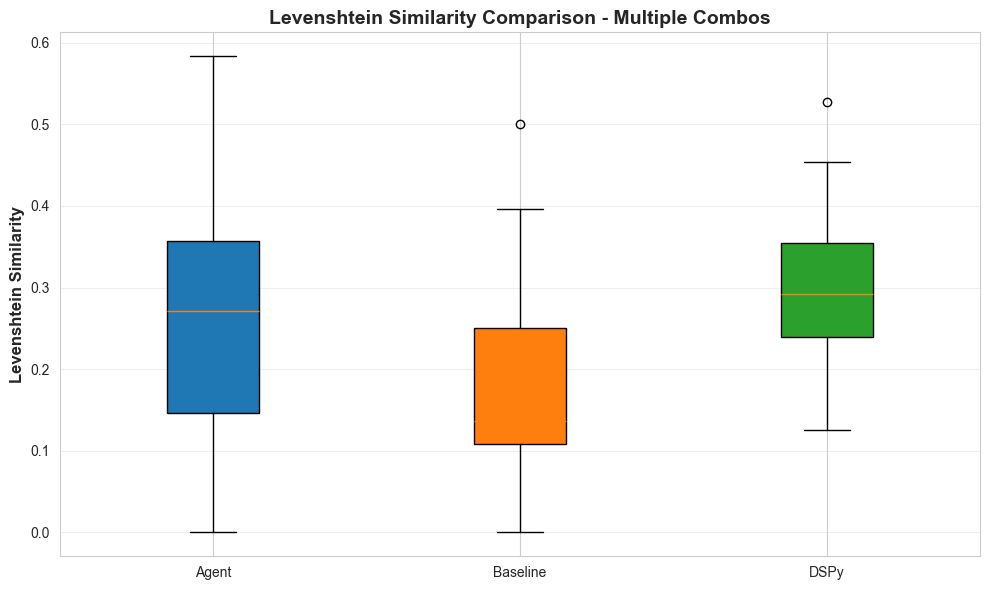

In [97]:
# Create comparison of Levenshtein similarities
lev_mult_comparison_df = pd.DataFrame({
    'Agent': lev_mult_agent,
    'Baseline': lev_mult_baseline,
    'DSPy': lev_mult_dspy
})

print("Levenshtein Similarity Statistics (Multiple Combos)")
print("=" * 60)
print(lev_mult_comparison_df.describe().round(4))

# Visualize distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Levenshtein Similarity Distribution - Multiple Combos', fontsize=14, fontweight='bold')

axes[0].hist(lev_mult_agent, bins=20, color=COLORS['Agent'], alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(lev_mult_agent), color='red', linestyle='--', linewidth=2, 
                label=f'Mean: {np.mean(lev_mult_agent):.3f}')
axes[0].set_title('Agent', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Levenshtein Similarity')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(lev_mult_baseline, bins=20, color=COLORS['Baseline'], alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(lev_mult_baseline), color='red', linestyle='--', linewidth=2, 
                label=f'Mean: {np.mean(lev_mult_baseline):.3f}')
axes[1].set_title('Baseline', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Levenshtein Similarity')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].hist(lev_mult_dspy, bins=20, color=COLORS['DSPy'], alpha=0.7, edgecolor='black')
axes[2].axvline(np.mean(lev_mult_dspy), color='red', linestyle='--', linewidth=2, 
               label=f'Mean: {np.mean(lev_mult_dspy):.3f}')
axes[2].set_title('DSPy', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Levenshtein Similarity')
axes[2].set_ylabel('Frequency')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Box plot comparison
fig, ax = plt.subplots(figsize=(10, 6))
box_data = [lev_mult_agent, lev_mult_baseline, lev_mult_dspy]
bp = ax.boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)
bp['boxes'][0].set_facecolor(COLORS['Agent'])
bp['boxes'][1].set_facecolor(COLORS['Baseline'])
bp['boxes'][2].set_facecolor(COLORS['DSPy'])
ax.set_ylabel('Levenshtein Similarity', fontsize=12, fontweight='bold')
ax.set_title('Levenshtein Similarity Comparison - Multiple Combos', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### 4.5 Pause Recognition Analysis


C:\Users\bpohl\AppData\Local\Temp\ipykernel_28748\987033257.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)


Combo Boundary Accuracy Statistics (Pause Recognition)
         Agent  Baseline     DSPy
count  24.0000   24.0000  24.0000
mean    0.4817    0.4986   0.4236
std     0.2174    0.1324   0.1746
min     0.0000    0.3333   0.1818
25%     0.3833    0.4000   0.2857
50%     0.5000    0.5000   0.3667
75%     0.5952    0.5000   0.5714
max     0.8000    1.0000   0.8571


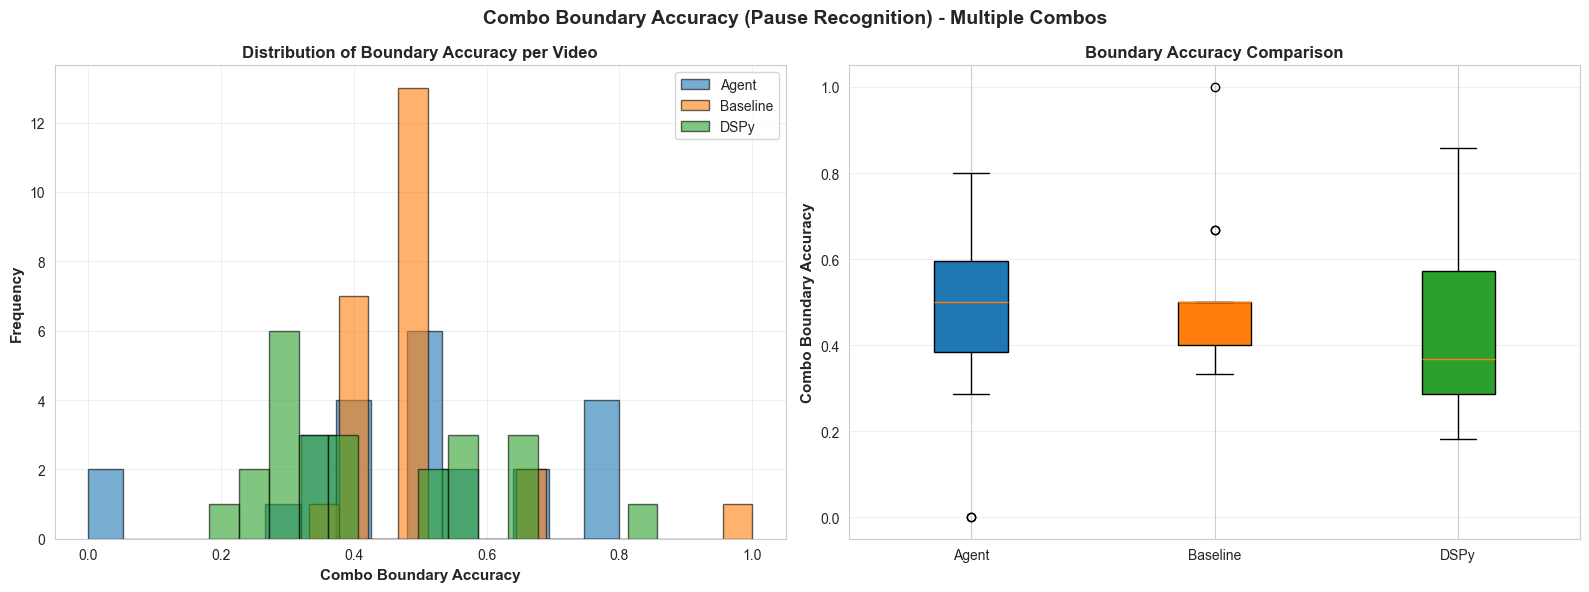


Average Combo Boundary Accuracy (Pause Recognition):
  Agent:    0.4817 ± 0.2128
  Baseline: 0.4986 ± 0.1296
  DSPy:     0.4236 ± 0.1709

Best pause recognition: Baseline (0.4986)


In [98]:
# Analyze combo boundary accuracy (pause recognition)
boundary_comparison_df = pd.DataFrame({
    'Agent': boundary_agent,
    'Baseline': boundary_baseline,
    'DSPy': boundary_dspy
})

print("Combo Boundary Accuracy Statistics (Pause Recognition)")
print("=" * 60)
print(boundary_comparison_df.describe().round(4))

# Visualize boundary accuracy
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Combo Boundary Accuracy (Pause Recognition) - Multiple Combos', 
             fontsize=14, fontweight='bold')

# Histogram
axes[0].hist(boundary_agent, bins=15, alpha=0.6, label='Agent', color=COLORS['Agent'], edgecolor='black')
axes[0].hist(boundary_baseline, bins=15, alpha=0.6, label='Baseline', color=COLORS['Baseline'], edgecolor='black')
axes[0].hist(boundary_dspy, bins=15, alpha=0.6, label='DSPy', color=COLORS['DSPy'], edgecolor='black')
axes[0].set_xlabel('Combo Boundary Accuracy', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0].set_title('Distribution of Boundary Accuracy per Video', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Box plot
box_data = [boundary_agent, boundary_baseline, boundary_dspy]
bp = axes[1].boxplot(box_data, labels=['Agent', 'Baseline', 'DSPy'], patch_artist=True)
bp['boxes'][0].set_facecolor(COLORS['Agent'])
bp['boxes'][1].set_facecolor(COLORS['Baseline'])
bp['boxes'][2].set_facecolor(COLORS['DSPy'])
axes[1].set_ylabel('Combo Boundary Accuracy', fontsize=11, fontweight='bold')
axes[1].set_title('Boundary Accuracy Comparison', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Per-video analysis
print("\nAverage Combo Boundary Accuracy (Pause Recognition):")
print(f"  Agent:    {np.mean(boundary_agent):.4f} ± {np.std(boundary_agent):.4f}")
print(f"  Baseline: {np.mean(boundary_baseline):.4f} ± {np.std(boundary_baseline):.4f}")
print(f"  DSPy:     {np.mean(boundary_dspy):.4f} ± {np.std(boundary_dspy):.4f}")

best_boundary = max(np.mean(boundary_agent), np.mean(boundary_baseline), np.mean(boundary_dspy))
if np.mean(boundary_agent) == best_boundary:
    best_boundary_name = 'Agent'
elif np.mean(boundary_baseline) == best_boundary:
    best_boundary_name = 'Baseline'
else:
    best_boundary_name = 'DSPy'
print(f"\nBest pause recognition: {best_boundary_name} ({best_boundary:.4f})")


## Section 5: Summary and Insights


In [99]:
# Create overall comparison table across all tasks
summary_data = {
    'Task': [],
    'Metric': [],
    'Agent': [],
    'Baseline': [],
    'DSPy': [],
    'Best': []
}

# Individual strikes
summary_data['Task'].extend(['Individual Strikes'] * 4)
summary_data['Metric'].extend(['Accuracy', 'Macro F1', 'Micro F1', 'Weighted F1'])
summary_data['Agent'].extend([
    metrics_agent['accuracy'],
    metrics_agent['macro_f1'],
    metrics_agent['micro_f1'],
    metrics_agent['weighted_f1']
])
summary_data['Baseline'].extend([
    metrics_baseline['accuracy'],
    metrics_baseline['macro_f1'],
    metrics_baseline['micro_f1'],
    metrics_baseline['weighted_f1']
])
summary_data['DSPy'].extend([
    metrics_dspy['accuracy'],
    metrics_dspy['macro_f1'],
    metrics_dspy['micro_f1'],
    metrics_dspy['weighted_f1']
])

# Single combos
summary_data['Task'].extend(['Single Combos'] * 5)
summary_data['Metric'].extend([
    'Exact Match Accuracy', 'Sequence Accuracy', 'Levenshtein Similarity',
    'Macro F1', 'Micro F1'
])
summary_data['Agent'].extend([
    combo_agent['metrics']['exact_match_accuracy'],
    combo_agent['metrics']['average_sequence_accuracy'],
    np.mean(lev_agent),
    metrics_combo_agent['macro_f1'],
    metrics_combo_agent['micro_f1']
])
summary_data['Baseline'].extend([
    combo_baseline['metrics']['exact_match_accuracy'],
    combo_baseline['metrics']['average_sequence_accuracy'],
    np.mean(lev_baseline),
    metrics_combo_baseline['macro_f1'],
    metrics_combo_baseline['micro_f1']
])
summary_data['DSPy'].extend([
    combo_dspy['metrics']['exact_match_accuracy'],
    combo_dspy['metrics']['average_sequence_accuracy'],
    np.mean(lev_dspy),
    metrics_combo_dspy['macro_f1'],
    metrics_combo_dspy['micro_f1']
])

# Multiple combos
summary_data['Task'].extend(['Multiple Combos'] * 8)
summary_data['Metric'].extend([
    'Exact Match Accuracy', 'Sequence Accuracy', 'Combo Count Accuracy',
    'Boundary Accuracy (Pause)', 'Combo-Wise Accuracy', 'Levenshtein Similarity',
    'Macro F1', 'Micro F1'
])
summary_data['Agent'].extend([
    multiple_agent['metrics']['exact_match_accuracy'],
    multiple_agent['metrics']['average_sequence_accuracy'],
    multiple_agent['metrics']['average_combo_count_accuracy'],
    multiple_agent['metrics'].get('average_combo_boundary_accuracy', multiple_agent['metrics'].get('average_boundary_accuracy', 0.0)),
    multiple_agent['metrics']['average_combo_wise_accuracy'],
    np.mean(lev_mult_agent),
    metrics_mult_agent['macro_f1'],
    metrics_mult_agent['micro_f1']
])
summary_data['Baseline'].extend([
    multiple_baseline['metrics']['exact_match_accuracy'],
    multiple_baseline['metrics']['average_sequence_accuracy'],
    multiple_baseline['metrics']['average_combo_count_accuracy'],
    multiple_baseline['metrics'].get('average_boundary_accuracy', multiple_baseline['metrics'].get('average_combo_boundary_accuracy', 0.0)),
    multiple_baseline['metrics']['average_combo_wise_accuracy'],
    np.mean(lev_mult_baseline),
    metrics_mult_baseline['macro_f1'],
    metrics_mult_baseline['micro_f1']
])
summary_data['DSPy'].extend([
    multiple_dspy['metrics']['exact_match_accuracy'],
    multiple_dspy['metrics']['average_sequence_accuracy'],
    multiple_dspy['metrics']['average_combo_count_accuracy'],
    multiple_dspy['metrics'].get('average_combo_boundary_accuracy', multiple_dspy['metrics'].get('average_boundary_accuracy', 0.0)),
    multiple_dspy['metrics']['average_combo_wise_accuracy'],
    np.mean(lev_mult_dspy),
    metrics_mult_dspy['macro_f1'],
    metrics_mult_dspy['micro_f1']
])

# Determine best for each metric
for i in range(len(summary_data['Task'])):
    agent_val = summary_data['Agent'][i]
    baseline_val = summary_data['Baseline'][i]
    dspy_val = summary_data['DSPy'][i]
    best_val = max(agent_val, baseline_val, dspy_val)
    if agent_val == best_val:
        summary_data['Best'].append('Agent')
    elif baseline_val == best_val:
        summary_data['Best'].append('Baseline')
    else:
        summary_data['Best'].append('DSPy')

summary_df = pd.DataFrame(summary_data)
print("Overall Summary - All Tasks and Approaches")
print("=" * 100)
pd.set_option('display.max_rows', None)
print(summary_df.round(4))


Overall Summary - All Tasks and Approaches
                  Task               Metric   Agent  Baseline    DSPy  \
0   Individual Strikes             Accuracy  0.1483    0.1466  0.1429   
1   Individual Strikes             Macro F1  0.0901    0.1026  0.1321   
2   Individual Strikes             Micro F1  0.1483    0.1466  0.1429   
3   Individual Strikes          Weighted F1  0.0903    0.1026  0.1321   
4        Single Combos  Exact Match Accu...  0.0400    0.0000  0.1200   
5        Single Combos    Sequence Accuracy  0.3000    0.3200  0.3993   
6        Single Combos  Levenshtein Simi...  0.4258    0.4372  0.5148   
7        Single Combos             Macro F1  0.0541    0.0544  0.0770   
8        Single Combos             Micro F1  0.2200    0.1935  0.2644   
9      Multiple Combos  Exact Match Accu...  0.0000    0.0000  0.0000   
10     Multiple Combos    Sequence Accuracy  0.1223    0.1349  0.2016   
11     Multiple Combos  Combo Count Accu...  0.6692    0.3799  0.7764   
12     M

In [100]:
# Count wins per approach
wins = summary_df['Best'].value_counts()
print("\n" + "=" * 60)
print("Best Performing Approach Summary")
print("=" * 60)
print(f"Agent:    {wins.get('Agent', 0)} metrics")
print(f"Baseline: {wins.get('Baseline', 0)} metrics")
print(f"DSPy:     {wins.get('DSPy', 0)} metrics")

# Key findings
print("\n" + "=" * 60)
print("Key Findings")
print("=" * 60)

# Individual strikes findings
print("\n1. Individual Strikes:")
best_ind_acc = summary_df[(summary_df['Task'] == 'Individual Strikes') & 
                          (summary_df['Metric'] == 'Accuracy')]['Best'].values[0]
print(f"   - Best accuracy: {best_ind_acc}")
best_ind_f1 = summary_df[(summary_df['Task'] == 'Individual Strikes') & 
                        (summary_df['Metric'] == 'Macro F1')]['Best'].values[0]
print(f"   - Best macro F1: {best_ind_f1}")

# Single combos findings
print("\n2. Single Combos:")
best_combo_lev = summary_df[(summary_df['Task'] == 'Single Combos') & 
                           (summary_df['Metric'] == 'Levenshtein Similarity')]['Best'].values[0]
print(f"   - Best Levenshtein similarity: {best_combo_lev}")
best_combo_seq = summary_df[(summary_df['Task'] == 'Single Combos') & 
                           (summary_df['Metric'] == 'Sequence Accuracy')]['Best'].values[0]
print(f"   - Best sequence accuracy: {best_combo_seq}")

# Multiple combos findings
print("\n3. Multiple Combos:")
best_mult_boundary = summary_df[(summary_df['Task'] == 'Multiple Combos') & 
                               (summary_df['Metric'] == 'Boundary Accuracy (Pause)')]['Best'].values[0]
print(f"   - Best pause recognition (boundary accuracy): {best_mult_boundary}")
best_mult_lev = summary_df[(summary_df['Task'] == 'Multiple Combos') & 
                          (summary_df['Metric'] == 'Levenshtein Similarity')]['Best'].values[0]
print(f"   - Best Levenshtein similarity: {best_mult_lev}")
best_mult_count = summary_df[(summary_df['Task'] == 'Multiple Combos') & 
                            (summary_df['Metric'] == 'Combo Count Accuracy')]['Best'].values[0]
print(f"   - Best combo count accuracy: {best_mult_count}")

print("\n" + "=" * 60)
print("Recommendations")
print("=" * 60)
print("Based on the comprehensive analysis:")
print("1. For individual strike classification, consider the approach with highest accuracy and F1")
print("2. For sequence tasks (combos), Levenshtein similarity provides insight into sequence-level performance")
print("3. For multiple combos, boundary accuracy is crucial for detecting pauses between combos")
print("4. Consider ensemble approaches combining strengths of different methods")
print("5. Per-class analysis reveals which strike types are most challenging across all approaches")



Best Performing Approach Summary
Agent:    4 metrics
Baseline: 2 metrics
DSPy:     11 metrics

Key Findings

1. Individual Strikes:
   - Best accuracy: Agent
   - Best macro F1: DSPy

2. Single Combos:
   - Best Levenshtein similarity: DSPy
   - Best sequence accuracy: DSPy

3. Multiple Combos:
   - Best pause recognition (boundary accuracy): Baseline
   - Best Levenshtein similarity: DSPy
   - Best combo count accuracy: DSPy

Recommendations
Based on the comprehensive analysis:
1. For individual strike classification, consider the approach with highest accuracy and F1
2. For sequence tasks (combos), Levenshtein similarity provides insight into sequence-level performance
3. For multiple combos, boundary accuracy is crucial for detecting pauses between combos
4. Consider ensemble approaches combining strengths of different methods
5. Per-class analysis reveals which strike types are most challenging across all approaches
